In [ ]:
# ============================================================
# CELL 1 — SETUP AND RECOVER EXISTING PROJECT
# ============================================================

%pip -q install \
    "segmentation-models-pytorch==0.5.0" \
    "albumentations==2.0.8" \
    loguru timm einops rasterio earthengine-api \
    requests matplotlib pandas geopandas shapely \
    pyproj folium gdown

from google.colab import drive
from pathlib import Path
from IPython.display import display
import importlib.util
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

# Your personal Google Cloud project
EE_PROJECT = "just-terminus-512006-j1"

# Recovered project
REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

SH1_OUT = REPO / "outputs/kaikoura_full_coast_SH1"
R70_OUT = REPO / "outputs/kaikoura_route70"
FIG_OUT = REPO / "outputs/final_presentation_figures"

R70_OUT.mkdir(parents=True, exist_ok=True)
FIG_OUT.mkdir(parents=True, exist_ok=True)

assert REPO.exists(), f"Repository missing: {REPO}"

assert (SH1_OUT / "00_summary.json").exists(), (
    "Recovered SH1 results not found."
)

assert (SH1_OUT / "03_predicted_landslides.geojson").exists(), (
    "Recovered SH1 predictions not found."
)

assert (REPO / "src/model_utils.py").exists(), (
    "Model source code missing from recovered repository."
)

# Find the actual working full-corridor runner
candidates = list(
    (REPO / "scripts").glob("*full*sh1*corridor*.py")
)

candidates += list(
    (REPO / "scripts").glob("*full*corridor*.py")
)

candidates = list(dict.fromkeys(candidates))

assert candidates, (
    "Full-corridor runner missing. "
    "We need scripts/full_sh1_corridor.py "
    "from the recovered repository."
)

MODULE_PATH = candidates[0]

spec = importlib.util.spec_from_file_location(
    "working_corridor_model",
    MODULE_PATH
)

cnn_runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cnn_runner)

print("✅ Working CNN runner:", MODULE_PATH)

# Connect to Earth Engine
import ee

try:
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:
    ee.Authenticate(force=True)
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("✅ Earth Engine connected:", EE_PROJECT)

# Verify existing SH1 results
summary = json.loads(
    (SH1_OUT / "00_summary.json").read_text()
)

print("\n" + "=" * 60)
print("PROJECT RECOVERY")
print("=" * 60)

print("SH1 tiles:", summary.get("tile_count"))
print(
    "SH1 CNN polygons:",
    summary.get("reported_landslide_polygons")
)

print("New Route 70 output:", R70_OUT)
print("Presentation figures:", FIG_OUT)

print("\n✅ Ready for Cell 2")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 5.8 MB/s eta 0:00:00
Mounted at /content/drive
✅ Working CNN runner: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/scripts/kaikoura_full_sh1_corridor.py
✅ Earth Engine connected: just-terminus-512006-j1

PROJECT RECOVERY
SH1 tiles: 82
SH1 CNN polygons: 713
New Route 70 output: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/kaikoura_route70
Presentation figures: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures

✅ Ready for Cell 2


Trying: https://router.project-osrm.org/route/v1/driving/
Waypoint snapping distances (m): [3033, 1, 1712, 1]
Mapped road length: 77.8 km

Road names returned by router:
 • State Highway 1
 • Inland Kaikōura Road
 • Inland Road
 • Leslie Street
 • Lowry Street

Distance on roads named 'Inland': 77.2 km

INLAND ROUTE 70
Mapped route length: 77.83 km
Geometry points: 2240


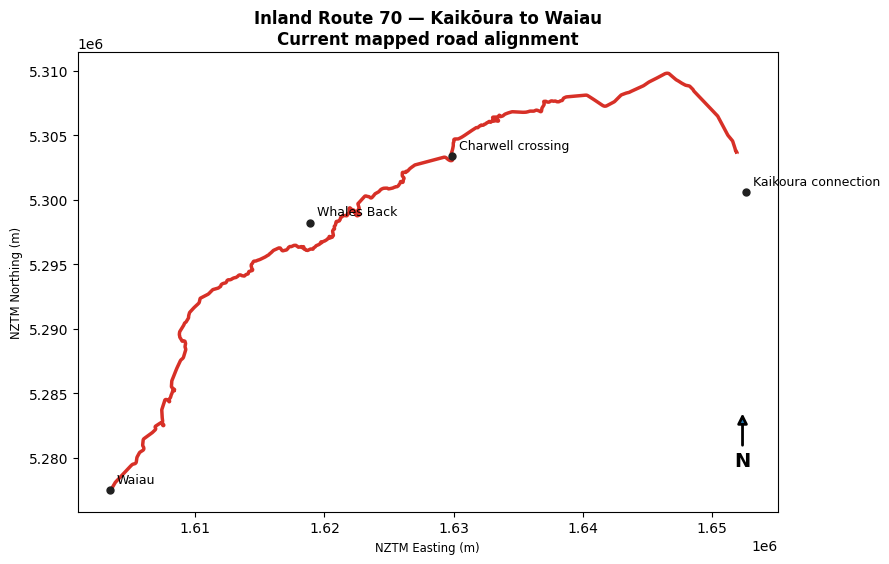


✅ Route 70 geometry saved: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/kaikoura_route70/01_route70_osm_current.geojson
✅ Route verification figure saved

NEXT: Inspect the route before running Cell 3.


In [ ]:
# ============================================================
# CELL 2 — FIXED INLAND ROUTE 70 DOWNLOAD
#
# Kaikoura → Inland Road → Waiau
# Uses actual mapped roads through OSRM
#
# No Overpass API
# No CNN inference yet
# ============================================================

import json
import requests
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path
from shapely.geometry import LineString, Point, mapping
from pyproj import Transformer
from IPython.display import display

R70_FILE = R70_OUT / "01_route70_osm_current.geojson"

# ------------------------------------------------------------
# 1. DEFINE ROUTE CONTROL POINTS
# ------------------------------------------------------------

# Approximate northern connection near Peketa / SH1.
# The routing service snaps this to the road network.
KAIKOURA_END = (173.64, -42.445)

# Published NZTM location of the Charwell River crossing
# on Inland Kaikoura Road.
# This forces the route through the inland corridor.
to_wgs84 = Transformer.from_crs(
    "EPSG:2193",
    "EPSG:4326",
    always_xy=True
)

CHARWELL_CROSSING = to_wgs84.transform(
    1629886,
    5303395
)

# Waiau township
WAIAU = (173.041, -42.655)

# Control point near the Whales Back section.
WHALES_BACK = (173.230, -42.468)

WAYPOINTS = [
    KAIKOURA_END,
    CHARWELL_CROSSING,
    WHALES_BACK,
    WAIAU
]

# ------------------------------------------------------------
# 2. DOWNLOAD REAL ROAD ROUTE
# ------------------------------------------------------------

def fetch_osrm_route():

    coords = ";".join(
        f"{lon:.6f},{lat:.6f}"
        for lon, lat in WAYPOINTS
    )

    services = [
        (
            "https://router.project-osrm.org/"
            "route/v1/driving/"
        ),
        (
            "https://routing.openstreetmap.de/"
            "routed-car/route/v1/driving/"
        )
    ]

    params = {
        "overview": "full",
        "geometries": "geojson",
        "steps": "true",
        "alternatives": "false"
    }

    errors = []

    for service in services:

        try:
            print("Trying:", service)

            response = requests.get(
                service + coords,
                params=params,
                timeout=90,
                headers={
                    "User-Agent":
                    "GEOG761-University-Research/1.0"
                }
            )

            response.raise_for_status()

            data = response.json()

            if data.get("code") != "Ok":
                raise RuntimeError(
                    str(data.get("message", data))
                )

            route = data["routes"][0]

            # Validate that control points were snapped
            # reasonably close to the requested locations.
            snap_distances = [
                float(w.get("distance", 0))
                for w in data.get("waypoints", [])
            ]

            print(
                "Waypoint snapping distances (m):",
                [round(d) for d in snap_distances]
            )

            if (
                len(snap_distances) != len(WAYPOINTS)
                or max(snap_distances) > 5000
            ):
                raise RuntimeError(
                    "One or more control points snapped "
                    "too far from the requested location."
                )

            return route

        except Exception as exc:

            errors.append(
                f"{service}: {exc}"
            )

            print(
                "Service unavailable or unsuitable:",
                str(exc)[:180]
            )

    raise RuntimeError(
        "Neither routing service returned a valid road.\n"
        + "\n".join(errors)
    )


# ------------------------------------------------------------
# 3. LOAD CACHED OR DOWNLOAD
# ------------------------------------------------------------

if R70_FILE.exists():

    print("✅ Reusing cached Route 70 geometry")

    route70 = gpd.read_file(R70_FILE)

else:

    print("Downloading Inland Route 70...")

    route = fetch_osrm_route()

    coordinates = route["geometry"]["coordinates"]

    assert len(coordinates) > 20, (
        "Returned route geometry is unexpectedly short."
    )

    line = LineString(coordinates)

    # Calculate route distance independently in NZTM.
    route_length_km = (
        gpd.GeoSeries(
            [line], crs="EPSG:4326"
        )
        .to_crs("EPSG:2193")
        .length.iloc[0] / 1000
    )

    print(
        "Mapped road length:",
        round(route_length_km, 1),
        "km"
    )

    # Kaikoura to Waiau should be approximately
    # 90–110 km, depending on selected endpoints.
    if not (75 <= route_length_km <= 140):

        raise RuntimeError(
            f"Unexpected route length: "
            f"{route_length_km:.1f} km.\n"
            "The routing service may have selected "
            "an unrelated detour. Do not process it."
        )

    # Check which actual road names the routing
    # service selected.
    road_names = []
    inland_distance_m = 0

    for leg in route.get("legs", []):

        for step in leg.get("steps", []):

            name = str(step.get("name", ""))

            if name:
                road_names.append(name)

            if "inland" in name.lower():
                inland_distance_m += float(
                    step.get("distance", 0)
                )

    print("\nRoad names returned by router:")

    for name in dict.fromkeys(road_names):
        print(" •", name)

    print(
        "\nDistance on roads named 'Inland':",
        round(inland_distance_m / 1000, 1),
        "km"
    )

    if inland_distance_m < 25000:

        raise RuntimeError(
            "The returned route includes less than "
            "25 km of roads named 'Inland'.\n"
            "It may have followed the wrong roads. "
            "Inspect the route before proceeding."
        )

    features = [{
        "type": "Feature",
        "properties": {
            "name": "Inland Route 70",
            "ref": "70",
            "source": "Current OSM road routing via OSRM",
            "note": (
                "Modern mapped geometry; "
                "not confirmed 2016 road alignment"
            )
        },
        "geometry": mapping(line)
    }]

    R70_FILE.write_text(
        json.dumps({
            "type": "FeatureCollection",
            "features": features
        })
    )

    route70 = gpd.read_file(R70_FILE)

# ------------------------------------------------------------
# 4. VERIFY FINAL ROUTE
# ------------------------------------------------------------

assert not route70.empty, (
    "Route 70 geometry is empty."
)

route70_nztm = route70.to_crs("EPSG:2193")

route_length_km = (
    route70_nztm.geometry.length.sum() / 1000
)

print("\n" + "=" * 60)
print("INLAND ROUTE 70")
print("=" * 60)

print(
    "Mapped route length:",
    round(route_length_km, 2),
    "km"
)

print(
    "Geometry points:",
    sum(
        len(geom.coords)
        for geom in route70.geometry
        if geom.geom_type == "LineString"
    )
)

# ------------------------------------------------------------
# 5. PLOT ROUTE FOR VISUAL VERIFICATION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 10))

route70_nztm.plot(
    ax=ax,
    color="#d73027",
    linewidth=2.5,
    label="Inland Route 70"
)

# Show approximate control points
to_nztm = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:2193",
    always_xy=True
)

labels = [
    "Kaikoura connection",
    "Charwell crossing",
    "Whales Back",
    "Waiau"
]

for (lon, lat), label in zip(WAYPOINTS, labels):

    x, y = to_nztm.transform(lon, lat)

    ax.scatter(
        x, y,
        color="#202020",
        s=25,
        zorder=5
    )

    ax.annotate(
        label,
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Inland Route 70 — Kaikōura to Waiau\n"
    "Current mapped road alignment",
    fontweight="bold"
)

ax.set_xlabel("NZTM Easting (m)")
ax.set_ylabel("NZTM Northing (m)")
ax.set_aspect("equal")

# North arrow — bottom right
ax.annotate(
    "N",
    xy=(0.95, 0.22),
    xytext=(0.95, 0.10),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontweight="bold",
    fontsize=14,
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2
    )
)

plt.tight_layout()

fig.savefig(
    R70_OUT / "01_route70_verification.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Route 70 geometry saved:", R70_FILE)
print("✅ Route verification figure saved")
print("\nNEXT: Inspect the route before running Cell 3.")

ROUTE 70 CNN PROCESSING PLAN
Road features: 1
CNN tiles: 58
Processing resolution: 10 m
Model input: 384 × 384 pixels
Evaluation core: 256 × 256 pixels
Road buffer: 1000 m
Kaikoura vicinity: nearest mapped road 4.9 km away
Waiau: nearest mapped road 0.4 km away


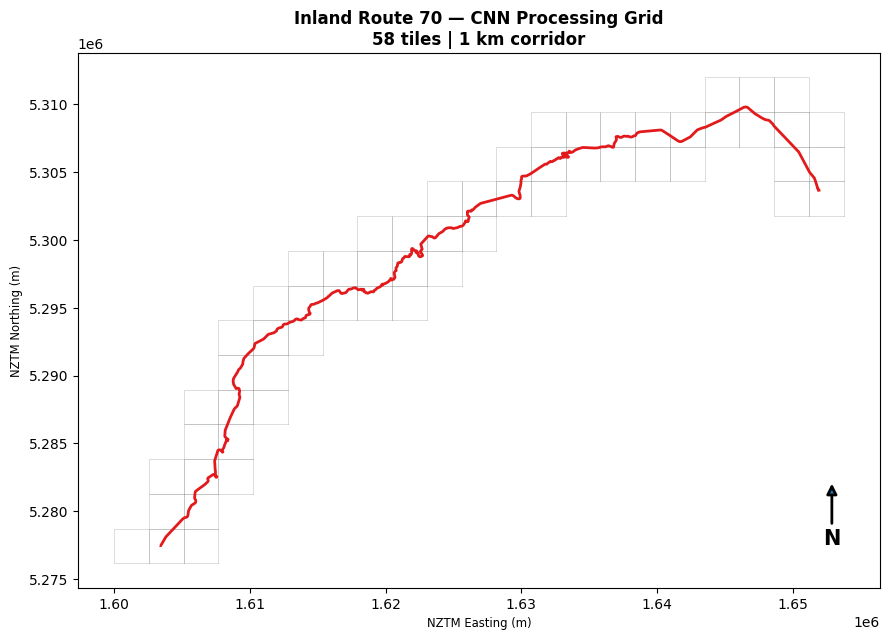


✅ Route 70 planning complete


In [ ]:
# ============================================================
# CELL 3 — ROUTE 70 CNN TILE PLANNING
# ============================================================

from shapely.geometry import shape, Point
from shapely.ops import unary_union
from pyproj import Transformer
import math
import matplotlib.pyplot as plt

r70_features = json.loads(
    R70_FILE.read_text()
)["features"]

r70_tiles, r70_road_union = cnn_runner.build_tiles(
    r70_features,
    R70_OUT,
    buffer_m=1000
)

print("=" * 60)
print("ROUTE 70 CNN PROCESSING PLAN")
print("=" * 60)

print("Road features:", len(r70_features))
print("CNN tiles:", len(r70_tiles))
print("Processing resolution: 10 m")
print("Model input: 384 × 384 pixels")
print("Evaluation core: 256 × 256 pixels")
print("Road buffer: 1000 m")

assert len(r70_tiles) > 0, "No Route 70 tiles generated."

# Check the mapped road extends into both endpoint areas.
project = Transformer.from_crs(
    "EPSG:4326", "EPSG:2193",
    always_xy=True
)

endpoints = {
    "Kaikoura vicinity": (173.58, -42.44),
    "Waiau": (173.04, -42.65)
}

for name, (lon, lat) in endpoints.items():
    x, y = project.transform(lon, lat)

    distance = r70_road_union.distance(
        Point(x, y)
    ) / 1000

    print(
        f"{name}: nearest mapped road "
        f"{distance:.1f} km away"
    )

    if distance > 12:
        raise RuntimeError(
            f"Route 70 geometry does not extend "
            f"close enough to {name}. "
            "Check OSM coverage before proceeding."
        )

# Plot actual geometry and all processing tiles
fig, ax = plt.subplots(figsize=(9, 10))

for tile in r70_tiles:
    x, y = tile["core"].exterior.xy
    ax.plot(
        x, y,
        color="#888888",
        linewidth=0.4,
        alpha=0.5
    )

route70_nztm.plot(
    ax=ax,
    color="#e31a1c",
    linewidth=2
)

ax.set_aspect("equal")

ax.set_title(
    f"Inland Route 70 — CNN Processing Grid\n"
    f"{len(r70_tiles)} tiles | 1 km corridor",
    fontweight="bold"
)

ax.set_xlabel("NZTM Easting (m)")
ax.set_ylabel("NZTM Northing (m)")

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.20),
    xytext=(0.94, 0.08),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontweight="bold",
    fontsize=15,
    arrowprops=dict(
        arrowstyle="-|>",
        linewidth=2
    )
)

plt.tight_layout()

fig.savefig(
    FIG_OUT / "01_Route70_processing_grid.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Route 70 planning complete")

In [ ]:
# ============================================================
# QUICK CHECK — VERIFY CNN RUNNER BEFORE 58-TILE INFERENCE
# ============================================================

import inspect

required = [
    "checkpoint_ready",
    "load_model",
    "process_tile",
    "merge_detections",
    "classify_roads"
]

print("CNN RUNNER COMPATIBILITY CHECK")
print("=" * 55)

all_ok = True

for name in required:
    func = getattr(cnn_runner, name, None)

    if callable(func):
        print(f"✅ {name}{inspect.signature(func)}")
    else:
        print(f"❌ {name} — NOT FOUND")
        all_ok = False

print("\nFirst Route 70 tile fields:")
print(list(r70_tiles[0].keys()))

print("\nTotal planned tiles:", len(r70_tiles))

if all_ok:
    print("\n✅ All expected functions exist.")
else:
    print("\n⚠️ We need to adapt Cell 4 to the actual runner.")

CNN RUNNER COMPATIBILITY CHECK
✅ checkpoint_ready(repo)
✅ load_model(repo)
✅ process_tile(ee, model, tile, out, threshold=0.5)
✅ merge_detections(tiles, out)
✅ classify_roads(features, predicted, masks, out, segment_m=200)

First Route 70 tile fields:
['tile_id', 'ix', 'iy', 'xmin', 'ymax', 'core_coverage_pct', 'core', 'input']

Total planned tiles: 58

✅ All expected functions exist.


In [ ]:
# ============================================================
# CELL 4 — RUN CNN ON ENTIRE ROUTE 70
# Existing official pretrained model
# No Kaikoura training or threshold tuning
# ============================================================

import time

print("=" * 60)
print("ROUTE 70 — CNN INFERENCE")
print("=" * 60)

print("Checking official pretrained weights...")

# This verifies the official checkpoint and downloads it
# if it is missing from your personal Drive.
checkpoint = cnn_runner.checkpoint_ready(REPO)

print("✅ Checkpoint:", checkpoint)

print("\nLoading pretrained CNN...")

model = cnn_runner.load_model(REPO)

print("✅ CNN loaded")
print("✅ No model retraining")
print("✅ Fixed threshold = 0.5")

# None means process every tile.
# Keep None for the full corridor.
MAX_NEW_TILES = None

THRESHOLD = 0.5

statuses = []
new_tiles = 0

start_time = time.time()

for i, tile in enumerate(r70_tiles, 1):

    tile_id = tile["tile_id"]

    status_file = (
        R70_OUT / "tile_results"
        / tile_id / "status.json"
    )

    previously_complete = False

    if status_file.exists():
        old = json.loads(status_file.read_text())

        binary_file = (
            status_file.parent / "binary.tif"
        )

        previously_complete = (
            old.get("state") in [
                "processed", "unobserved"
            ]
            and old.get("threshold") == THRESHOLD
            and binary_file.exists()
        )

    if (
        MAX_NEW_TILES is not None
        and new_tiles >= MAX_NEW_TILES
        and not previously_complete
    ):
        print("Reached requested new-tile limit.")
        break

    print(
        f"\n[{i}/{len(r70_tiles)}] {tile_id}",
        flush=True
    )

    status = cnn_runner.process_tile(
        ee,
        model,
        tile,
        R70_OUT,
        threshold=THRESHOLD
    )

    statuses.append(status)

    if not previously_complete:
        new_tiles += 1

    print(
        "State:", status["state"],
        "| Valid pixels:",
        status.get("valid_pixels", 0),
        "| Predicted pixels:",
        status.get("predicted_pixels", 0),
        flush=True
    )

    if i % 5 == 0 or i == len(r70_tiles):

        progress = {
            "tiles_reached": i,
            "total_tiles": len(r70_tiles),
            "processed": sum(
                x["state"] == "processed"
                for x in statuses
            ),
            "unobserved": sum(
                x["state"] == "unobserved"
                for x in statuses
            ),
            "failed": sum(
                x["state"] == "failed"
                for x in statuses
            ),
            "elapsed_minutes": round(
                (time.time() - start_time) / 60,
                2
            )
        }

        (R70_OUT / "progress.json").write_text(
            json.dumps(progress, indent=2)
        )

        print("\nPROGRESS:", progress, flush=True)

print("\n" + "=" * 60)
print("ROUTE 70 INFERENCE PASS FINISHED")
print("=" * 60)

print(
    "Elapsed:",
    round((time.time() - start_time) / 60, 1),
    "minutes"
)

print("New tiles attempted:", new_tiles)
print("Total planned tiles:", len(r70_tiles))

del model

print("\n✅ Proceed to Cell 5")

ROUTE 70 — CNN INFERENCE
Checking official pretrained weights...


Downloading...
From (original): https://drive.google.com/uc?id=1Z6FOqWJ2ZmiJetrP48pXZiHSzizjZKdj
From (redirected): https://drive.google.com/uc?id=1Z6FOqWJ2ZmiJetrP48pXZiHSzizjZKdj&confirm=t&uuid=461de2c8-b4cc-482a-9be9-42f6657e8309
To: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/checkpoints/official/unet_r50_diff.pt.part
100%|██████████| 131M/131M [00:02<00:00, 57.5MB/s]


✅ Checkpoint: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/checkpoints/official/unet_r50_diff.pt

Loading pretrained CNN...


/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/src/models/bit/networks.py:234: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if with_pos is 'learned':
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/src/models/bit/networks.py:265: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if self.pool_mode is 'max':
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/src/models/bit/networks.py:267: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif self.pool_mode is 'ave':


✅ CNN loaded
✅ No model retraining
✅ Fixed threshold = 0.5

[1/58] C_625_2061


...

State: processed | Valid pixels: 65536 | Predicted pixels: 0

[55/58] C_644_2074


State: processed | Valid pixels: 65536 | Predicted pixels: 584

PROGRESS: {'tiles_reached': 55, 'total_tiles': 58, 'processed': 55, 'unobserved': 0, 'failed': 0, 'elapsed_minutes': 10.4}

[56/58] C_645_2071


State: processed | Valid pixels: 65536 | Predicted pixels: 21

[57/58] C_645_2072


State: processed | Valid pixels: 65536 | Predicted pixels: 3

[58/58] C_645_2073


State: processed | Valid pixels: 65536 | Predicted pixels: 408

PROGRESS: {'tiles_reached': 58, 'total_tiles': 58, 'processed': 58, 'unobserved': 0, 'failed': 0, 'elapsed_minutes': 10.93}

ROUTE 70 INFERENCE PASS FINISHED
Elapsed: 10.9 minutes
New tiles attempted: 58
Total planned tiles: 58

✅ Proceed to Cell 5


In [ ]:
# ============================================================
# CELL 5 — MERGE ROUTE 70 CNN RESULTS
# + ASSESS ROAD SEGMENTS
# ============================================================

import json
import geopandas as gpd

print("Combining georeferenced CNN predictions...")

merged, polygons, masks, tile_counts = (
    cnn_runner.merge_detections(
        r70_tiles,
        R70_OUT
    )
)

print("✅ CNN polygons:", len(polygons))
print("Tile states:", tile_counts)

print("\nClassifying Route 70 road sections...")

road_rows, road_features = (
    cnn_runner.classify_roads(
        r70_features,
        merged,
        masks,
        R70_OUT,
        segment_m=200
    )
)

summary70 = {
    "corridor": "Inland Route 70",
    "planned_tiles": len(r70_tiles),
    "tile_counts": tile_counts,
    "cnn_polygons": len(polygons),
    "road_segments": len(road_rows),
    "road_length_km": round(
        route70_nztm.geometry.length.sum() / 1000,
        2
    ),
    "model_threshold": 0.5,
    "input": "Historical Sentinel-2 L1C 2016",
    "reference_data_used_for_inference": False
}

(R70_OUT / "00_summary.json").write_text(
    json.dumps(summary70, indent=2)
)

print("\n" + "=" * 60)
print("ROUTE 70 RESULTS")
print("=" * 60)

print(json.dumps(summary70, indent=2))

road_df70 = pd.DataFrame(road_rows)

print("\nRoad classification counts:")

display(
    road_df70["class"]
    .value_counts()
    .rename_axis("Classification")
    .reset_index(name="Segments")
)

print("\n✅ Route 70 predictions saved:")
print(R70_OUT / "03_predicted_landslides.geojson")

print("\n✅ Route 70 road assessment saved:")
print(R70_OUT / "04_SH1_road_assessment.geojson")

if tile_counts.get("failed", 0) > 0:
    print(
        "\n⚠️ Some tiles failed. "
        "These areas are not confirmed clear."
    )

Combining georeferenced CNN predictions...
✅ CNN polygons: 642
Tile states: {'processed': 58, 'unobserved': 0, 'failed': 0}

Classifying Route 70 road sections...

ROUTE 70 RESULTS
{
  "corridor": "Inland Route 70",
  "planned_tiles": 58,
  "tile_counts": {
    "processed": 58,
    "unobserved": 0,
    "failed": 0
  },
  "cnn_polygons": 642,
  "road_segments": 390,
  "road_length_km": 77.83,
  "model_threshold": 0.5,
  "input": "Historical Sentinel-2 L1C 2016",
  "reference_data_used_for_inference": false
}

Road classification counts:


,Classification,Segments
0,no_detected_landslide_not_safe,286
1,inspection_priority,48
2,possible_impingement,38
3,unknown_insufficient_imagery,18



✅ Route 70 predictions saved:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/kaikoura_route70/03_predicted_landslides.geojson

✅ Route 70 road assessment saved:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/kaikoura_route70/04_SH1_road_assessment.geojson


In [ ]:
# ============================================================
# CELL 6 — THREE-CORRIDOR GNS VALIDATION
#
# SH1 North
# SH1 South
# Inland Route 70
#
# Primary matching threshold: 50 m
# Sensitivity threshold: 100 m
# ============================================================

import json
import math
import requests
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd

from shapely.geometry import box
from shapely.ops import unary_union
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD EXISTING SH1 RESULTS
# ------------------------------------------------------------

sh1 = gpd.read_file(
    SH1_OUT / "01_sh1_osm_current.geojson"
).to_crs("EPSG:4326")

pred_sh1 = gpd.read_file(
    SH1_OUT / "03_predicted_landslides.geojson"
).to_crs("EPSG:2193")

pred70 = gpd.read_file(
    R70_OUT / "03_predicted_landslides.geojson"
).to_crs("EPSG:2193")

# ------------------------------------------------------------
# 2. SEPARATE SH1 NORTH AND SOUTH
# ------------------------------------------------------------

DIVIDER_LAT = -42.40

def clip_lines(gdf, region):

    result = gdf.copy()

    result["geometry"] = (
        result.geometry.intersection(region)
    )

    result = result[
        result.geometry.notna()
        & ~result.geometry.is_empty
    ].copy()

    result = result[
        result.geometry.length > 0
    ].copy()

    return result


sh1_north = clip_lines(
    sh1,
    box(172, DIVIDER_LAT, 175, -41)
).to_crs("EPSG:2193")

sh1_south = clip_lines(
    sh1,
    box(172, -44, 175, DIVIDER_LAT)
).to_crs("EPSG:2193")

# Split existing CNN polygons by centroid latitude
pred_centres = pred_sh1.to_crs(
    "EPSG:4326"
).geometry.representative_point()

pred_north = pred_sh1[
    pred_centres.y >= DIVIDER_LAT
].copy()

pred_south = pred_sh1[
    pred_centres.y < DIVIDER_LAT
].copy()

# ------------------------------------------------------------
# 3. DEFINE THE THREE CORRIDORS
# ------------------------------------------------------------

CORRIDORS = {
    "SH1 North": {
        "roads": sh1_north,
        "pred": pred_north,
        "out": SH1_OUT
    },
    "SH1 South": {
        "roads": sh1_south,
        "pred": pred_south,
        "out": SH1_OUT
    },
    "Route 70": {
        "roads": route70_nztm,
        "pred": pred70,
        "out": R70_OUT
    }
}

road_unions = {
    name: unary_union(data["roads"].geometry)
    for name, data in CORRIDORS.items()
}

all_roads = unary_union(
    list(road_unions.values())
)

# ------------------------------------------------------------
# 4. DOWNLOAD GNS SOURCE LOCATIONS
# ------------------------------------------------------------

GNS_CACHE = (
    FIG_OUT / "all_corridor_GNS_sources.geojson"
)

if GNS_CACHE.exists():

    print("✅ Reusing cached GNS observations")

    gns = gpd.read_file(
        GNS_CACHE
    ).to_crs("EPSG:2193")

else:

    print("Downloading GNS Science inventory...")

    GNS_URL = (
        "https://gis.gns.cri.nz/server/rest/"
        "services/EILD/EILD_V2_Map/MapServer/0/query"
    )

    xmin, ymin, xmax, ymax = (
        all_roads.buffer(1200).bounds
    )

    all_features = []
    offset = 0

    while True:

        params = {
            "where": "1=1",
            "geometry": (
                f"{xmin},{ymin},{xmax},{ymax}"
            ),
            "geometryType": "esriGeometryEnvelope",
            "inSR": 2193,
            "outSR": 4326,
            "spatialRel": "esriSpatialRelIntersects",
            "outFields": "objectid,source_id",
            "returnGeometry": "true",
            "resultRecordCount": 1000,
            "resultOffset": offset,
            "f": "geojson"
        }

        response = requests.get(
            GNS_URL,
            params=params,
            timeout=90
        )

        response.raise_for_status()

        payload = response.json()

        if "error" in payload:
            raise RuntimeError(
                str(payload["error"])
            )

        batch = payload.get("features", [])

        all_features.extend(batch)

        print(
            "GNS records downloaded:",
            len(all_features),
            end="\r"
        )

        if len(batch) < 1000:
            break

        offset += 1000

        if offset > 100000:
            raise RuntimeError(
                "Unexpected GNS pagination size."
            )

    assert all_features, (
        "No GNS records returned."
    )

    gns = gpd.GeoDataFrame.from_features(
        all_features,
        crs="EPSG:4326"
    ).to_crs("EPSG:2193")

    if "objectid" in gns.columns:
        gns = gns.drop_duplicates(
            subset=["objectid"]
        )

    gns = gns[
        gns.geometry.notna()
        & ~gns.geometry.is_empty
        & (gns.geom_type == "Point")
    ].copy()

    gns.to_crs("EPSG:4326").to_file(
        GNS_CACHE,
        driver="GeoJSON"
    )

print("\nGNS records loaded:", len(gns))

# ------------------------------------------------------------
# 5. ASSIGN EACH SOURCE TO ITS NEAREST ROAD CORRIDOR
# ------------------------------------------------------------

gns = gns.reset_index(drop=True)

names = list(CORRIDORS)

distance_columns = []

for name in names:

    col = f"distance_{names.index(name)}"

    gns[col] = gns.geometry.distance(
        road_unions[name]
    )

    distance_columns.append(col)

distance_matrix = gns[
    distance_columns
].to_numpy()

nearest_index = np.argmin(
    distance_matrix,
    axis=1
)

minimum_distance = np.min(
    distance_matrix,
    axis=1
)

gns["corridor"] = [
    names[i] for i in nearest_index
]

gns["distance_to_road_m"] = (
    minimum_distance
)

gns = gns[
    gns["distance_to_road_m"] <= 1000
].copy().reset_index(drop=True)

print(
    "GNS sources within three corridors:",
    len(gns)
)

# ------------------------------------------------------------
# 6. DETERMINE OBSERVABILITY FROM ACTUAL CNN MASKS
# ------------------------------------------------------------

gns["observed"] = False

CORE_M = 2560

for name, data in CORRIDORS.items():

    indices = gns.index[
        gns["corridor"] == name
    ].tolist()

    grouped = {}

    for idx in indices:

        point = gns.geometry.iloc[idx]

        ix = math.floor(
            point.x / CORE_M
        )

        iy = math.floor(
            point.y / CORE_M
        )

        tile_id = f"C_{ix}_{iy}"

        grouped.setdefault(
            tile_id, []
        ).append(idx)

    for tile_id, point_indices in grouped.items():

        binary_file = (
            data["out"]
            / "tile_results"
            / tile_id
            / "binary.tif"
        )

        if not binary_file.exists():
            continue

        coordinates = [
            (
                gns.geometry.iloc[i].x,
                gns.geometry.iloc[i].y
            )
            for i in point_indices
        ]

        with rasterio.open(binary_file) as src:

            values = [
                int(v[0])
                for v in src.sample(
                    coordinates
                )
            ]

        for idx, value in zip(
            point_indices, values
        ):

            gns.at[idx, "observed"] = (
                value in (0, 1)
            )

# ------------------------------------------------------------
# 7. MATCH GNS POINTS TO CNN PREDICTIONS
# ------------------------------------------------------------

gns["match_status"] = "UNOBSERVED"

for name, data in CORRIDORS.items():

    predictions = data["pred"].reset_index(
        drop=True
    )

    spatial_index = (
        predictions.sindex
        if not predictions.empty
        else None
    )

    indices = gns.index[
        gns["corridor"] == name
    ]

    for idx in indices:

        if not gns.at[idx, "observed"]:
            continue

        point = gns.geometry.iloc[idx]

        if spatial_index is None:
            candidates = []
        else:
            candidates = spatial_index.query(
                point.buffer(100),
                predicate="intersects"
            )

        if len(candidates) == 0:

            gns.at[idx, "match_status"] = (
                "MISSED"
            )

            continue

        nearest_distance = min(
            point.distance(
                predictions.geometry.iloc[int(j)]
            )
            for j in candidates
        )

        if nearest_distance <= 50:

            status = "MATCHED_50M"

        elif nearest_distance <= 100:

            status = "NEAR_100M"

        else:

            status = "MISSED"

        gns.at[idx, "match_status"] = status

# ------------------------------------------------------------
# 8. CALCULATE STATISTICS FOR EACH CORRIDOR
# ------------------------------------------------------------

rows = []

for name in names:

    subset = gns[
        gns["corridor"] == name
    ]

    counts = subset[
        "match_status"
    ].value_counts()

    matched = int(
        counts.get("MATCHED_50M", 0)
    )

    near = int(
        counts.get("NEAR_100M", 0)
    )

    missed = int(
        counts.get("MISSED", 0)
    )

    unobserved = int(
        counts.get("UNOBSERVED", 0)
    )

    observed = matched + near + missed

    total = len(subset)

    rate50 = (
        100 * matched / observed
        if observed
        else np.nan
    )

    rate100 = (
        100 * (matched + near) / observed
        if observed
        else np.nan
    )

    rows.append({
        "corridor": name,
        "GNS_total": total,
        "observed": observed,
        "unobserved": unobserved,
        "matched_50m": matched,
        "near_50_to_100m": near,
        "missed_over_100m": missed,
        "observable_pct": (
            100 * observed / total
            if total else np.nan
        ),
        "matched_50m_pct": rate50,
        "matched_100m_pct": rate100,
        "missed_over_100m_pct": (
            100 * missed / observed
            if observed else np.nan
        ),
        "CNN_polygons": len(
            CORRIDORS[name]["pred"]
        )
    })

stats = pd.DataFrame(rows)

# ------------------------------------------------------------
# 9. THREE-CORRIDOR OVERALL STATISTICS
# ------------------------------------------------------------

complete = (
    len(stats) == 3
    and (stats["observed"] > 0).all()
)

if complete:

    mean50 = stats[
        "matched_50m_pct"
    ].mean()

    mean100 = stats[
        "matched_100m_pct"
    ].mean()

else:

    mean50 = np.nan
    mean100 = np.nan

total_observed = int(
    stats["observed"].sum()
)

total_matched50 = int(
    stats["matched_50m"].sum()
)

total_matched100 = int(
    (
        stats["matched_50m"]
        + stats["near_50_to_100m"]
    ).sum()
)

pooled50 = (
    100 * total_matched50 / total_observed
    if total_observed else np.nan
)

pooled100 = (
    100 * total_matched100 / total_observed
    if total_observed else np.nan
)

print("\n" + "=" * 75)
print("THREE-CORRIDOR VALIDATION RESULTS")
print("=" * 75)

display(stats.round(2))

print("\n" + "=" * 75)
print("OVERALL PERFORMANCE")
print("=" * 75)

print(
    f"Mean of three corridor rates — 50 m: "
    f"{mean50:.2f}%"
)

print(
    f"Mean of three corridor rates — 100 m: "
    f"{mean100:.2f}%"
)

print(
    f"Pooled GNS matching rate — 50 m: "
    f"{pooled50:.2f}%"
)

print(
    f"Pooled GNS matching rate — 100 m: "
    f"{pooled100:.2f}%"
)

print(
    f"Total observable GNS points: "
    f"{total_observed:,}"
)

if not complete:
    print(
        "\n⚠️ Three-corridor average unavailable: "
        "one or more corridors has zero observed GNS points."
    )

# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

stats.to_csv(
    FIG_OUT / "three_corridor_statistics.csv",
    index=False
)

gns.to_crs("EPSG:4326").to_file(
    FIG_OUT / "three_corridor_GNS_classification.geojson",
    driver="GeoJSON"
)

overall = {
    "mean_corridor_rate_50m_pct": (
        float(mean50)
        if np.isfinite(mean50) else None
    ),
    "mean_corridor_rate_100m_pct": (
        float(mean100)
        if np.isfinite(mean100) else None
    ),
    "pooled_rate_50m_pct": (
        float(pooled50)
        if np.isfinite(pooled50) else None
    ),
    "pooled_rate_100m_pct": (
        float(pooled100)
        if np.isfinite(pooled100) else None
    ),
    "total_observed_gns": total_observed,
    "total_matched_50m": total_matched50,
    "total_matched_100m": total_matched100,
    "matching_thresholds_m": [50, 100],
    "corridor_buffer_m": 1000,
    "note": (
        "Retrospective source-point spatial matching, "
        "not overall model accuracy or road-closure probability."
    )
}

(
    FIG_OUT / "three_corridor_overall_statistics.json"
).write_text(
    json.dumps(overall, indent=2)
)

print("\n✅ Statistics saved to:", FIG_OUT)

/tmp/ipykernel_3208/2096212716.py:55: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since the calling GeoSeries contains empty geometries, the result has changed compared to previous versions of GeoPandas.
Given a GeoSeries 's', you can use '~s.is_empty & s.notna()' to get back the old behaviour.

To further ignore this warning, you can do: 
import warnings; warnings.filterwarnings('ignore', 'GeoSeries.notna', UserWarning)
  result.geometry.notna()
/tmp/ipykernel_3208/2096212716.py:60: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  result.geometry.length > 0
/tmp/ipykernel_3208/2096212716.py:55: UserWarning: GeoSeries.notna() previously returned False for both missing (None) and empty geometries. Now, it only returns False for missing values. Since


GNS records loaded: 23704
GNS sources within three corridors: 2750

THREE-CORRIDOR VALIDATION RESULTS


,corridor,GNS_total,observed,unobserved,matched_50m,near_50_to_100m,missed_over_100m,observable_pct,matched_50m_pct,matched_100m_pct,missed_over_100m_pct,CNN_polygons
0,SH1 North,1595,1595,0,950,174,471,100.00,59.56,70.47,29.53,381
1,SH1 South,587,476,111,237,41,198,81.09,49.79,58.40,41.60,332
2,Route 70,568,493,75,339,38,116,86.80,68.76,76.47,23.53,642



OVERALL PERFORMANCE
Mean of three corridor rates — 50 m: 59.37%
Mean of three corridor rates — 100 m: 68.45%
Pooled GNS matching rate — 50 m: 59.52%
Pooled GNS matching rate — 100 m: 69.38%
Total observable GNS points: 2,564

✅ Statistics saved to: /content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures


In [ ]:
# ============================================================
# CHECK ROAD ASSESSMENT DATA BEFORE MAKING FINAL FIGURES
# ============================================================

import geopandas as gpd

for name, folder in [
    ("SH1", SH1_OUT),
    ("Route 70", R70_OUT)
]:
    path = folder / "04_SH1_road_assessment.geojson"

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    roads_check = gpd.read_file(path)

    print("Road segments:", len(roads_check))
    print("Available columns:")
    print(roads_check.columns.tolist())

    if "class" in roads_check.columns:
        print("\nOriginal road classifications:")
        print(roads_check["class"].value_counts())

    print("\nFirst two records:")
    display(roads_check.drop(columns="geometry").head(2))


SH1
Road segments: 589
Available columns:
['segment_id', 'class', 'length_m', 'visible_fraction', 'distance_to_detection_m', 'geometry']

Original road classifications:
class
no_detected_landslide_not_safe    324
possible_impingement              125
inspection_priority                96
unknown_insufficient_imagery       44
Name: count, dtype: int64

First two records:


,segment_id,class,length_m,visible_fraction,distance_to_detection_m
0,SH1_0000_000,no_detected_landslide_not_safe,189.8,1.0,922.2
1,SH1_0000_001,no_detected_landslide_not_safe,189.8,1.0,1007.0



Route 70
Road segments: 390
Available columns:
['segment_id', 'class', 'length_m', 'visible_fraction', 'distance_to_detection_m', 'geometry']

Original road classifications:
class
no_detected_landslide_not_safe    286
inspection_priority                48
possible_impingement               38
unknown_insufficient_imagery       18
Name: count, dtype: int64

First two records:


,segment_id,class,length_m,visible_fraction,distance_to_detection_m
0,SH1_0000_000,no_detected_landslide_not_safe,199.6,1.0,422.0
1,SH1_0000_001,no_detected_landslide_not_safe,199.6,1.0,253.2


In [ ]:
#this better work bruh cell 7
# ============================================================
# CELL 7 — INLAND ROUTE 70
# HISTORICAL 2016 SATELLITE + CNN + GNS
#
# SAME SATELLITE METHOD AS ORIGINAL SUCCESSFUL SH1 FIGURE
#
# OUTPUT 1: CNN POLYGONS ONLY
# OUTPUT 2: CNN POLYGONS + GNS COMPARISON
#
# - Actual November/December 2016 Sentinel-2 imagery
# - Cloud-masked / unavailable areas displayed grey
# - Original CNN polygons unchanged
# - Actual GNS classifications from Cell 6
# - North arrow and scale bar
# - TWO INDIVIDUAL HIGH-RESOLUTION PNGs
#
# NO CNN INFERENCE
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
from io import BytesIO

import json
import math
import requests

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

from PIL import Image
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display


# ============================================================
# 1. FILE PATHS
# ============================================================

EE_PROJECT = "just-terminus-512006-j1"

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

R70_OUT = REPO / "outputs/kaikoura_route70"

FIG_OUT = (
    REPO / "outputs/final_presentation_figures"
)

SAVE_DIR = FIG_OUT / "ROUTE70_PRESENTATION"

SAVE_DIR.mkdir(parents=True, exist_ok=True)

CNN_FILE = (
    R70_OUT / "03_predicted_landslides.geojson"
)

ROAD_FILE = (
    R70_OUT / "01_route70_osm_current.geojson"
)

GNS_FILE = (
    FIG_OUT / "three_corridor_GNS_classification.geojson"
)

for f in [CNN_FILE, ROAD_FILE, GNS_FILE]:
    assert f.exists(), f"Missing file: {f}"

print("=" * 65)
print("INLAND ROUTE 70 — PRESENTATION FIGURES")
print("=" * 65)


# ============================================================
# 2. LOAD EXISTING RESULTS
# ============================================================

pred = gpd.read_file(
    CNN_FILE
).to_crs("EPSG:4326")

roads = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:4326")

gns_all = gpd.read_file(
    GNS_FILE
).to_crs("EPSG:4326")

gns = gns_all[
    gns_all["corridor"] == "Route 70"
].copy()

assert not roads.empty
assert not pred.empty
assert not gns.empty

print("\nRoute 70 CNN polygons:", len(pred))
print("Route 70 GNS source points:", len(gns))

# Use the classifications we ALREADY calculated.
# Do not independently recalculate or tune matching.

counts = gns["match_status"].value_counts()

matched = int(
    counts.get("MATCHED_50M", 0)
)

near = int(
    counts.get("NEAR_100M", 0)
)

missed = int(
    counts.get("MISSED", 0)
)

unobserved = int(
    counts.get("UNOBSERVED", 0)
)

n_observed = matched + near + missed

rate_50 = (
    100 * matched / n_observed
    if n_observed else float("nan")
)

rate_100 = (
    100 * (matched + near) / n_observed
    if n_observed else float("nan")
)

print("\nGNS MATCHING STATISTICS")
print("-" * 45)

print(f"Matched ≤50 m:       {matched}")
print(f"Near match 50–100 m: {near}")
print(f"Missed >100 m:       {missed}")
print(f"Unobserved:          {unobserved}")

print(f"\n50 m matching rate:  {rate_50:.2f}%")
print(f"100 m matching rate: {rate_100:.2f}%")


# ============================================================
# 3. CONNECT GOOGLE EARTH ENGINE
# ============================================================

try:
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("\n✅ Earth Engine connected")


# ============================================================
# 4. DEFINE ROUTE 70 STUDY AREA
# ============================================================

# SAME APPROACH AS THE ORIGINAL SUCCESSFUL SH1 FIGURE:
#
# Use the actual road bounds in longitude/latitude.
# Add a small geographic margin.
# Render satellite imagery directly in EPSG:4326.

minlon, minlat, maxlon, maxlat = roads.total_bounds

lon_margin = 0.025
lat_margin = 0.020

minlon -= lon_margin
maxlon += lon_margin

minlat -= lat_margin
maxlat += lat_margin

region = ee.Geometry.Rectangle(
    [minlon, minlat, maxlon, maxlat]
)

print("\nStudy area:")

print(
    f"Longitude: {minlon:.4f} to {maxlon:.4f}"
)

print(
    f"Latitude:  {minlat:.4f} to {maxlat:.4f}"
)


# ============================================================
# 5. HISTORICAL 2016 SATELLITE IMAGERY
# ============================================================

POST_START = "2016-11-20"
POST_END = "2016-12-10"

collection = (
    ee.ImageCollection(
        "COPERNICUS/S2_HARMONIZED"
    )
    .filterBounds(region)
    .filterDate(
        POST_START,
        POST_END
    )
)

n_scenes = collection.size().getInfo()

print("\nHistorical Sentinel-2 scenes:", n_scenes)

assert n_scenes > 0, (
    "No historical satellite images available."
)


# ============================================================
# 6. MASK CLOUDS
# ============================================================

# Same QA60 cloud-masking method as original figure.
#
# Opaque clouds = bit 10
# Cirrus clouds = bit 11
#
# Pixels without any valid cloud-free observation
# will be displayed grey.

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


# ============================================================
# 7. CREATE HISTORICAL SATELLITE MOSAIC
# ============================================================

# IMPORTANT:
#
# This restores the EXACT working logic:
#
# 1. Historical Sentinel-2 image collection
# 2. QA60 cloud masking
# 3. Scene cloud-percentage sorting
# 4. Mosaic
# 5. RGB reflectance visualisation
# 6. EPSG:4326 thumbnail
#
# Do NOT switch to the old broken GeoTIFF pipeline.

post_image = (
    collection
    .map(mask_clouds)
    .sort("CLOUDY_PIXEL_PERCENTAGE", False)
    .mosaic()
)

post_rgb = (
    post_image
    .select(["B4", "B3", "B2"])
    .multiply(0.0001)
    .visualize(
        min=0.02,
        max=0.30,
        gamma=1.15
    )
)

# Fill any pixels remaining masked after mosaicking
# with neutral grey.
#
# This does not mean every visible cloud is detected:
# it only applies to pixels masked by QA60 / missing data.

post_rgb = post_rgb.unmask(
    value=175,
    sameFootprint=False
)


# ============================================================
# 8. DOWNLOAD THE SATELLITE BACKGROUND
# ============================================================

BACKGROUND_FILE = (
    SAVE_DIR / "ROUTE70_HISTORICAL_2016_BACKGROUND.png"
)

# Larger output than the original map, while retaining
# the original WGS84 thumbnail method.

width = 2000

height = round(
    width * (maxlat - minlat) / (maxlon - minlon)
)

print("\nDownloading historical 2016 satellite imagery...")

print(
    f"Display dimensions: {width} × {height} pixels"
)

# Use cached GOOD imagery if it exists.
# This is a new cache file, unrelated to failed attempts.

if BACKGROUND_FILE.exists():

    background = Image.open(
        BACKGROUND_FILE
    ).convert("RGB")

    print("✅ Reusing saved Route 70 background")

else:

    thumb_url = post_rgb.getThumbURL({
        "region": region,
        "dimensions": f"{width}x{height}",
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        thumb_url,
        timeout=180
    )

    response.raise_for_status()

    background = Image.open(
        BytesIO(response.content)
    ).convert("RGB")


# ============================================================
# 9. VERIFY THE BACKGROUND IS NOT UNIFORM
# ============================================================

# We specifically reject the flat-colour backgrounds
# that appeared in the earlier figures.

preview_array = np.asarray(
    background.resize((300, 180))
)

unique_colours = len(
    np.unique(
        preview_array.reshape(-1, 3),
        axis=0
    )
)

print(
    "\nDistinct colours in satellite preview:",
    unique_colours
)

if unique_colours < 200:

    raise RuntimeError(
        "Satellite imagery appears nearly uniform. "
        "The figure will not be saved with a "
        "flat-colour background."
    )

background.save(BACKGROUND_FILE)

print("✅ Historical satellite background downloaded")
print("✅ Passed basic colour-variation check")


# ============================================================
# 10. MAP FORMATTING
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "figure.dpi": 130
})

PRED_COLOUR = "#ff4da6"
ROAD_COLOUR = "#ffe600"

point_styles = {

    "UNOBSERVED": {
        "color": "#bfbfbf",
        "size": 9,
        "z": 5
    },

    "MISSED": {
        "color": "#ff1744",
        "size": 13,
        "z": 6
    },

    "NEAR_100M": {
        "color": "#ff9800",
        "size": 15,
        "z": 7
    },

    "MATCHED_50M": {
        "color": "#00e676",
        "size": 13,
        "z": 8
    }
}


# ============================================================
# 11. NORTH ARROW + SCALE BAR
# ============================================================

def add_map_furniture(ax):

    # North arrow in bottom-right.

    ax.annotate(
        "N",
        xy=(0.94, 0.23),
        xytext=(0.94, 0.10),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold",
        color="white",
        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2.5
        ),
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.75,
            pad=3
        ),
        zorder=30
    )

    # 10 km scale bar.
    # Convert metres to longitude degrees at local latitude.

    scale_km = 10

    bar_lat = (
        minlat + 0.055 * (maxlat - minlat)
    )

    bar_lon = (
        minlon + 0.06 * (maxlon - minlon)
    )

    degrees_lon = (
        scale_km * 1000
        / (
            111320
            * math.cos(math.radians(bar_lat))
        )
    )

    ax.plot(
        [bar_lon, bar_lon + degrees_lon],
        [bar_lat, bar_lat],
        color="black",
        linewidth=7,
        solid_capstyle="butt",
        zorder=30
    )

    ax.plot(
        [bar_lon, bar_lon + degrees_lon],
        [bar_lat, bar_lat],
        color="white",
        linewidth=4,
        solid_capstyle="butt",
        zorder=31
    )

    ax.text(
        bar_lon + degrees_lon / 2,
        bar_lat + 0.009,
        "10 km",
        color="white",
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="bottom",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.75,
            pad=3
        ),
        zorder=32
    )


# ============================================================
# 12. CREATE THE MAP
# ============================================================

def create_route70_map(include_gns, output_path):

    fig, ax = plt.subplots(
        figsize=(14, 10),
        facecolor="white"
    )

    ax.set_facecolor("#afafaf")

    # --------------------------------------------------------
    # HISTORICAL SATELLITE IMAGE
    # --------------------------------------------------------

    ax.imshow(
        np.asarray(background),
        extent=(
            minlon,
            maxlon,
            minlat,
            maxlat
        ),
        origin="upper",
        interpolation="nearest",
        zorder=0
    )

    # --------------------------------------------------------
    # CNN LANDSLIDE POLYGONS
    # --------------------------------------------------------

    pred.plot(
        ax=ax,
        facecolor=PRED_COLOUR,
        edgecolor=PRED_COLOUR,
        linewidth=0.25,
        alpha=0.48,
        zorder=2
    )

    # --------------------------------------------------------
    # INLAND ROUTE 70
    # --------------------------------------------------------

    roads.plot(
        ax=ax,
        color=ROAD_COLOUR,
        linewidth=2.5,
        alpha=0.98,
        zorder=4
    )

    # --------------------------------------------------------
    # GNS POINTS — ONLY ON SECOND FIGURE
    # --------------------------------------------------------

    if include_gns:

        for status, style in point_styles.items():

            subset = gns[
                gns["match_status"] == status
            ]

            if subset.empty:
                continue

            subset.plot(
                ax=ax,
                color=style["color"],
                markersize=style["size"],
                edgecolor="#202020",
                linewidth=0.15,
                alpha=0.95,
                zorder=style["z"]
            )

    # --------------------------------------------------------
    # MAP EXTENT AND GEOGRAPHIC ASPECT
    # --------------------------------------------------------

    ax.set_xlim(minlon, maxlon)
    ax.set_ylim(minlat, maxlat)

    # Same geographic aspect correction as original figure.

    ax.set_aspect(
        1 / math.cos(
            math.radians(
                (minlat + maxlat) / 2
            )
        )
    )

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

    add_map_furniture(ax)

    # --------------------------------------------------------
    # LEGEND
    # --------------------------------------------------------

    legend_items = []

    if include_gns:

        legend_items.extend([

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#00e676",
                markeredgecolor="black",
                markersize=8,
                label=f"GNS matched ≤50 m ({matched:,})"
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#ff9800",
                markeredgecolor="black",
                markersize=8,
                label=f"GNS near match 50–100 m ({near:,})"
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#ff1744",
                markeredgecolor="black",
                markersize=8,
                label=f"GNS missed >100 m ({missed:,})"
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#bfbfbf",
                markeredgecolor="black",
                markersize=8,
                label=f"Unobserved ({unobserved:,})"
            )
        ])

    legend_items.extend([

        Patch(
            facecolor=PRED_COLOUR,
            edgecolor=PRED_COLOUR,
            alpha=0.55,
            label=(
                f"CNN predictions "
                f"({len(pred):,} polygons)"
            )
        ),

        Line2D(
            [], [],
            color=ROAD_COLOUR,
            linewidth=3,
            label="Inland Route 70"
        ),

        Patch(
            facecolor="#afafaf",
            edgecolor="#777777",
            label="Cloud-masked / no imagery"
        )
    ])

    ax.legend(
        handles=legend_items,
        loc="upper left",
        fontsize=10,
        facecolor="white",
        framealpha=0.95,
        edgecolor="#555555"
    )

    # --------------------------------------------------------
    # TITLES AND FOOTER
    # --------------------------------------------------------

    if include_gns:

        title = (
            "2016 Kaikōura Earthquake | Inland Route 70\n"
            "Independent GNS Source-Point Comparison"
        )

        footer = (
            f"GNS source-point matching: "
            f"{rate_50:.1f}% within 50 m | "
            f"{rate_100:.1f}% within 100 m "
            f"(n = {n_observed:,} observed sources)\n"
            "Background: Sentinel-2 post-earthquake "
            "composite, 20 Nov–9 Dec 2016. "
            "GNS used only for retrospective evaluation."
        )

    else:

        title = (
            "2016 Kaikōura Earthquake | Inland Route 70\n"
            "CNN Landslide Detections"
        )

        footer = (
            f"Pretrained Siamese U-Net: "
            f"{len(pred):,} candidate landslide polygons "
            f"along Inland Route 70.\n"
            "Background: Sentinel-2 post-earthquake "
            "composite, 20 Nov–9 Dec 2016. "
            "Detections do not confirm road closures."
        )

    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=18
    )

    fig.text(
        0.5,
        0.035,
        footer,
        fontsize=10,
        ha="center",
        va="center"
    )

    plt.tight_layout(
        rect=[0, 0.09, 1, 1]
    )

    # --------------------------------------------------------
    # SAVE HIGH-RESOLUTION PNG
    # --------------------------------------------------------

    fig.savefig(
        output_path,
        dpi=250,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print("✅ Saved:", output_path)


# ============================================================
# 13. FIGURE 1 — CNN PREDICTIONS ONLY
# ============================================================

print("\n" + "=" * 65)
print("FIGURE 1 — ROUTE 70 CNN PREDICTIONS")
print("=" * 65)

FIGURE_1 = (
    SAVE_DIR / "01_ROUTE70_CNN_ON_2016_SATELLITE.png"
)

create_route70_map(
    include_gns=False,
    output_path=FIGURE_1
)


# ============================================================
# 14. FIGURE 2 — CNN + GNS COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("FIGURE 2 — ROUTE 70 CNN vs GNS")
print("=" * 65)

FIGURE_2 = (
    SAVE_DIR / "02_ROUTE70_CNN_GNS_2016_SATELLITE.png"
)

create_route70_map(
    include_gns=True,
    output_path=FIGURE_2
)


# ============================================================
# 15. DONE
# ============================================================

print("\n" + "=" * 65)
print("✅ ROUTE 70 FIGURES COMPLETE")
print("=" * 65)

print("\nFigure 1:")
print(FIGURE_1)

print("\nFigure 2:")
print(FIGURE_2)

print("\nGNS results:")

print(
    f"50 m matching rate:  {rate_50:.2f}%"
)

print(
    f"100 m matching rate: {rate_100:.2f}%"
)

print(
    "\nNo CNN inference or retraining performed."
)

Output hidden; open in https://colab.research.google.com to view.

Now below we do the same for SH1 but for South and North

In [ ]:
# ============================================================
# CELL 8 — SH1 NORTH AND SH1 SOUTH
# HISTORICAL 2016 SATELLITE + CNN + GNS
#
# IDENTICAL APPROACH TO SUCCESSFUL ROUTE 70 FIGURES
#
# OUTPUTS:
#
# 1. SH1 NORTH — CNN predictions only
# 2. SH1 NORTH — CNN + GNS comparison
#
# 3. SH1 SOUTH — CNN predictions only
# 4. SH1 SOUTH — CNN + GNS comparison
#
# Historical 2016 Sentinel-2 satellite background
# CNN predictions in pink
# GNS matched sources in green
# GNS near matches in orange
# GNS missed sources in red
# Unobserved GNS sources in grey
# SH1 road alignment in yellow
#
# North arrow + scale bar
# Four individual high-resolution PNGs
#
# NO CNN INFERENCE
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
from io import BytesIO

import json
import math
import requests

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

from PIL import Image
from shapely.geometry import box
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ============================================================
# 1. CONFIGURATION
# ============================================================

EE_PROJECT = "just-terminus-512006-j1"

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

SH1_OUT = (
    REPO / "outputs/kaikoura_full_coast_SH1"
)

FIG_OUT = (
    REPO / "outputs/final_presentation_figures"
)

SAVE_DIR = (
    FIG_OUT / "SH1_NORTH_SOUTH_PRESENTATION"
)

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CNN_FILE = (
    SH1_OUT / "03_predicted_landslides.geojson"
)

ROAD_FILE = (
    SH1_OUT / "01_sh1_osm_current.geojson"
)

GNS_FILE = (
    FIG_OUT / "three_corridor_GNS_classification.geojson"
)

for file in [CNN_FILE, ROAD_FILE, GNS_FILE]:
    assert file.exists(), f"Missing file: {file}"

# Same earthquake date range used in the successful
# Route 70 presentation figures.

POST_START = "2016-11-20"
POST_END = "2016-12-10"

# Latitude dividing northern and southern SH1,
# consistent with the earlier Cell 6 evaluation.

DIVIDER_LAT = -42.40

# Colours identical to the Route 70 figures.

PRED_COLOUR = "#ff4da6"
ROAD_COLOUR = "#ffe600"

POINT_STYLES = {

    "UNOBSERVED": {
        "color": "#bfbfbf",
        "size": 9,
        "z": 5
    },

    "MISSED": {
        "color": "#ff1744",
        "size": 13,
        "z": 6
    },

    "NEAR_100M": {
        "color": "#ff9800",
        "size": 15,
        "z": 7
    },

    "MATCHED_50M": {
        "color": "#00e676",
        "size": 13,
        "z": 8
    }
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "figure.dpi": 130
})

print("=" * 70)
print("SH1 NORTH + SOUTH — HISTORICAL 2016 SATELLITE FIGURES")
print("=" * 70)


# ============================================================
# 2. LOAD EXISTING DATA
# ============================================================

roads_all = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:4326")

pred_all = gpd.read_file(
    CNN_FILE
).to_crs("EPSG:4326")

gns_all = gpd.read_file(
    GNS_FILE
).to_crs("EPSG:4326")

assert not roads_all.empty
assert not pred_all.empty
assert not gns_all.empty

print("\nOriginal SH1 data:")

print("Road features:", len(roads_all))
print("CNN polygons:", len(pred_all))
print("GNS sources:", len(gns_all))


# ============================================================
# 3. SPLIT SH1 NORTH AND SOUTH
# ============================================================

# Clip road geometries at the latitude boundary.
#
# This avoids displaying southern SH1 in northern maps
# and vice versa.

def clip_sh1_roads(roads, north=True):

    if north:

        region = box(
            172.0,
            DIVIDER_LAT,
            175.0,
            -41.0
        )

    else:

        region = box(
            172.0,
            -44.0,
            175.0,
            DIVIDER_LAT
        )

    result = roads.copy()

    result["geometry"] = (
        result.geometry.intersection(region)
    )

    result = result[
        result.geometry.notna()
        & ~result.geometry.is_empty
    ].copy()

    return result


# Assign CNN polygons to the same northern/southern
# groups used in the previous GNS evaluation.

pred_latitudes = (
    pred_all.geometry.representative_point().y
)

pred_north = pred_all[
    pred_latitudes >= DIVIDER_LAT
].copy()

pred_south = pred_all[
    pred_latitudes < DIVIDER_LAT
].copy()


roads_north = clip_sh1_roads(
    roads_all,
    north=True
)

roads_south = clip_sh1_roads(
    roads_all,
    north=False
)


gns_north = gns_all[
    gns_all["corridor"] == "SH1 North"
].copy()

gns_south = gns_all[
    gns_all["corridor"] == "SH1 South"
].copy()


CORRIDORS_SH1 = {

    "SH1 North": {
        "road": roads_north,
        "pred": pred_north,
        "gns": gns_north,
        "description": "Kaikōura to Clarence"
    },

    "SH1 South": {
        "road": roads_south,
        "pred": pred_south,
        "gns": gns_south,
        "description": "Oaro to Kaikōura"
    }
}


print("\n" + "=" * 65)
print("SH1 CORRIDOR SPLIT")
print("=" * 65)

for name, data in CORRIDORS_SH1.items():

    print(f"\n{name}")

    print(
        "Road features:",
        len(data["road"])
    )

    print(
        "CNN polygons:",
        len(data["pred"])
    )

    print(
        "GNS sources:",
        len(data["gns"])
    )


# ============================================================
# 4. CONNECT EARTH ENGINE
# ============================================================

try:

    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:

    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("\n✅ Google Earth Engine connected")


# ============================================================
# 5. CLOUD MASK — SAME AS SUCCESSFUL ROUTE 70
# ============================================================

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


# ============================================================
# 6. HISTORICAL 2016 SATELLITE BACKGROUND
# ============================================================

def get_historical_background(
    roads,
    corridor_name
):

    safe_name = (
        corridor_name
        .upper()
        .replace(" ", "_")
    )

    background_file = (
        SAVE_DIR
        / f"{safe_name}_HISTORICAL_2016_BACKGROUND.png"
    )

    # Get actual road extent in WGS84.

    minlon, minlat, maxlon, maxlat = (
        roads.total_bounds
    )

    # Same margins as successful Route 70 figure.

    lon_margin = 0.025
    lat_margin = 0.020

    minlon -= lon_margin
    maxlon += lon_margin

    minlat -= lat_margin
    maxlat += lat_margin

    bounds = (
        minlon,
        minlat,
        maxlon,
        maxlat
    )

    region = ee.Geometry.Rectangle(
        [
            minlon,
            minlat,
            maxlon,
            maxlat
        ]
    )

    # --------------------------------------------------------
    # Load historical Sentinel-2 observations
    # --------------------------------------------------------

    collection = (
        ee.ImageCollection(
            "COPERNICUS/S2_HARMONIZED"
        )
        .filterBounds(region)
        .filterDate(
            POST_START,
            POST_END
        )
    )

    scene_count = (
        collection.size().getInfo()
    )

    print(
        "\nHistorical Sentinel-2 scenes:",
        scene_count
    )

    if scene_count == 0:

        raise RuntimeError(
            f"No historical Sentinel-2 scenes "
            f"for {corridor_name}."
        )

    # --------------------------------------------------------
    # Original successful imagery-processing method
    # --------------------------------------------------------

    post_image = (
        collection
        .map(mask_clouds)
        .sort(
            "CLOUDY_PIXEL_PERCENTAGE",
            False
        )
        .mosaic()
    )

    post_rgb = (
        post_image
        .select(["B4", "B3", "B2"])
        .multiply(0.0001)
        .visualize(
            min=0.02,
            max=0.30,
            gamma=1.15
        )
    )

    # Fill remaining masked pixels with grey.
    # Clouds not detected by QA60 may still be visible.

    post_rgb = post_rgb.unmask(
        value=175,
        sameFootprint=False
    )

    # --------------------------------------------------------
    # Download satellite image
    # --------------------------------------------------------

    if background_file.exists():

        print(
            "✅ Reusing historical background:",
            background_file.name
        )

        background = Image.open(
            background_file
        ).convert("RGB")

    else:

        width = 2000

        height = round(
            width
            * (maxlat - minlat)
            / (maxlon - minlon)
        )

        print(
            "Downloading historical satellite imagery..."
        )

        print(
            f"Display size: {width} × {height}"
        )

        thumb_url = post_rgb.getThumbURL({

            "region": region,

            "dimensions": f"{width}x{height}",

            "crs": "EPSG:4326",

            "format": "png"

        })

        response = requests.get(
            thumb_url,
            timeout=180
        )

        response.raise_for_status()

        background = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

    # --------------------------------------------------------
    # Check background isn't obviously uniform
    # --------------------------------------------------------

    preview = np.asarray(
        background.resize((300, 180))
    )

    unique_colours = len(
        np.unique(
            preview.reshape(-1, 3),
            axis=0
        )
    )

    print(
        "Distinct background colours:",
        unique_colours
    )

    if unique_colours < 200:

        raise RuntimeError(
            f"{corridor_name}: Satellite background "
            "appears nearly uniform. "
            "Not saving a misleading figure."
        )

    background.save(background_file)

    print(
        "✅ Historical 2016 satellite imagery ready"
    )

    return background, bounds


# ============================================================
# 7. NORTH ARROW AND SCALE BAR
# ============================================================

def add_map_furniture_sh1(
    ax,
    bounds
):

    minlon, minlat, maxlon, maxlat = bounds

    # --------------------------------------------------------
    # North arrow — bottom right
    # --------------------------------------------------------

    ax.annotate(
        "N",

        xy=(0.94, 0.23),

        xytext=(0.94, 0.10),

        xycoords="axes fraction",

        textcoords="axes fraction",

        ha="center",

        va="center",

        fontsize=17,

        fontweight="bold",

        color="white",

        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2.5
        ),

        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.75,
            pad=3
        ),

        zorder=30
    )

    # --------------------------------------------------------
    # 5 km scale bar
    # --------------------------------------------------------

    scale_km = 5

    bar_lat = (
        minlat
        + 0.055 * (maxlat - minlat)
    )

    bar_lon = (
        minlon
        + 0.06 * (maxlon - minlon)
    )

    degrees_lon = (
        scale_km * 1000
        / (
            111320
            * math.cos(
                math.radians(bar_lat)
            )
        )
    )

    ax.plot(
        [
            bar_lon,
            bar_lon + degrees_lon
        ],
        [
            bar_lat,
            bar_lat
        ],
        color="black",
        linewidth=7,
        solid_capstyle="butt",
        zorder=30
    )

    ax.plot(
        [
            bar_lon,
            bar_lon + degrees_lon
        ],
        [
            bar_lat,
            bar_lat
        ],
        color="white",
        linewidth=4,
        solid_capstyle="butt",
        zorder=31
    )

    ax.text(
        bar_lon + degrees_lon / 2,
        bar_lat + 0.006,
        "5 km",
        color="white",
        fontsize=12,
        fontweight="bold",
        ha="center",
        va="bottom",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.75,
            pad=3
        ),
        zorder=32
    )


# ============================================================
# 8. GENERATE INDIVIDUAL SH1 FIGURE
# ============================================================

def create_sh1_map(
    corridor_name,
    data,
    background,
    bounds,
    include_gns,
    output_path
):

    roads = data["road"]
    pred = data["pred"]
    gns = data["gns"]

    minlon, minlat, maxlon, maxlat = bounds

    # --------------------------------------------------------
    # Calculate GNS statistics
    # --------------------------------------------------------

    counts = (
        gns["match_status"]
        .value_counts()
    )

    matched = int(
        counts.get("MATCHED_50M", 0)
    )

    near = int(
        counts.get("NEAR_100M", 0)
    )

    missed = int(
        counts.get("MISSED", 0)
    )

    unobserved = int(
        counts.get("UNOBSERVED", 0)
    )

    n_observed = (
        matched + near + missed
    )

    rate_50 = (
        100 * matched / n_observed
        if n_observed else float("nan")
    )

    rate_100 = (
        100 * (matched + near) / n_observed
        if n_observed else float("nan")
    )

    # --------------------------------------------------------
    # Create publication-style map
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(13, 13),
        facecolor="white"
    )

    ax.set_facecolor("#afafaf")

    # --------------------------------------------------------
    # Real historical 2016 satellite background
    # --------------------------------------------------------

    ax.imshow(
        np.asarray(background),

        extent=(
            minlon,
            maxlon,
            minlat,
            maxlat
        ),

        origin="upper",

        interpolation="nearest",

        zorder=0
    )

    # --------------------------------------------------------
    # CNN predicted landslide polygons
    # --------------------------------------------------------

    if not pred.empty:

        pred.plot(
            ax=ax,
            facecolor=PRED_COLOUR,
            edgecolor=PRED_COLOUR,
            linewidth=0.25,
            alpha=0.45,
            zorder=2
        )

    # --------------------------------------------------------
    # SH1 road alignment
    # --------------------------------------------------------

    roads.plot(
        ax=ax,
        color=ROAD_COLOUR,
        linewidth=2.2,
        alpha=0.98,
        zorder=4
    )

    # --------------------------------------------------------
    # GNS source points — ONLY comparison figure
    # --------------------------------------------------------

    if include_gns:

        for status, style in POINT_STYLES.items():

            subset = gns[
                gns["match_status"] == status
            ]

            if subset.empty:
                continue

            subset.plot(
                ax=ax,
                color=style["color"],
                markersize=style["size"],
                edgecolor="#202020",
                linewidth=0.15,
                alpha=0.95,
                zorder=style["z"]
            )

    # --------------------------------------------------------
    # Map extent and geographic aspect
    # --------------------------------------------------------

    ax.set_xlim(
        minlon,
        maxlon
    )

    ax.set_ylim(
        minlat,
        maxlat
    )

    ax.set_aspect(
        1 / math.cos(
            math.radians(
                (minlat + maxlat) / 2
            )
        )
    )

    ax.set_xlabel(
        "Longitude (°E)"
    )

    ax.set_ylabel(
        "Latitude (°N)"
    )

    add_map_furniture_sh1(
        ax,
        bounds
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    legend_items = []

    if include_gns:

        legend_items.extend([

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#00e676",
                markeredgecolor="black",
                markersize=8,
                label=(
                    f"GNS matched ≤50 m "
                    f"({matched:,})"
                )
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#ff9800",
                markeredgecolor="black",
                markersize=8,
                label=(
                    f"GNS near match 50–100 m "
                    f"({near:,})"
                )
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#ff1744",
                markeredgecolor="black",
                markersize=8,
                label=(
                    f"GNS missed >100 m "
                    f"({missed:,})"
                )
            ),

            Line2D(
                [], [],
                marker="o",
                linestyle="None",
                color="#bfbfbf",
                markeredgecolor="black",
                markersize=8,
                label=(
                    f"Unobserved "
                    f"({unobserved:,})"
                )
            )

        ])

    legend_items.extend([

        Patch(
            facecolor=PRED_COLOUR,
            edgecolor=PRED_COLOUR,
            alpha=0.55,
            label=(
                f"CNN predictions "
                f"({len(pred):,} polygons)"
            )
        ),

        Line2D(
            [], [],
            color=ROAD_COLOUR,
            linewidth=3,
            label="State Highway 1"
        ),

        Patch(
            facecolor="#afafaf",
            edgecolor="#777777",
            label="Cloud-masked / no imagery"
        )

    ])

    ax.legend(
        handles=legend_items,
        loc="upper left",
        fontsize=10,
        facecolor="white",
        framealpha=0.95,
        edgecolor="#555555"
    )

    # --------------------------------------------------------
    # Title and footer
    # --------------------------------------------------------

    if include_gns:

        title = (
            f"2016 Kaikōura Earthquake | {corridor_name}\n"
            "Independent GNS Source-Point Comparison"
        )

        footer = (
            f"GNS source-point matching: "
            f"{rate_50:.1f}% within 50 m | "
            f"{rate_100:.1f}% within 100 m "
            f"(n = {n_observed:,} observed sources)\n"
            "Background: Sentinel-2 post-earthquake "
            "composite, 20 Nov–9 Dec 2016. "
            "GNS used only for retrospective evaluation."
        )

    else:

        title = (
            f"2016 Kaikōura Earthquake | {corridor_name}\n"
            "CNN Landslide Detections"
        )

        footer = (
            f"Pretrained Siamese U-Net: "
            f"{len(pred):,} candidate landslide polygons "
            f"along {corridor_name}.\n"
            "Background: Sentinel-2 post-earthquake "
            "composite, 20 Nov–9 Dec 2016. "
            "Detections do not confirm road closures."
        )

    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=18
    )

    fig.text(
        0.5,
        0.035,
        footer,
        fontsize=10,
        ha="center",
        va="center"
    )

    plt.tight_layout(
        rect=[0, 0.09, 1, 1]
    )

    # --------------------------------------------------------
    # Save figure
    # --------------------------------------------------------

    fig.savefig(
        output_path,
        dpi=250,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    print(
        "✅ Saved:",
        output_path.name
    )

    return {
        "corridor": corridor_name,
        "matched_50m": matched,
        "near_50_to_100m": near,
        "missed_over_100m": missed,
        "unobserved": unobserved,
        "observed": n_observed,
        "rate_50m_percent": rate_50,
        "rate_100m_percent": rate_100
    }


# ============================================================
# 9. GENERATE ALL FOUR FIGURES
# ============================================================

ALL_RESULTS = []

for corridor_name, data in CORRIDORS_SH1.items():

    print("\n" + "=" * 70)
    print("PROCESSING:", corridor_name)
    print("=" * 70)

    print(
        "Corridor:",
        data["description"]
    )

    safe_name = (
        corridor_name
        .upper()
        .replace(" ", "_")
    )

    # --------------------------------------------------------
    # Get historical satellite imagery
    # --------------------------------------------------------

    background, bounds = get_historical_background(
        data["road"],
        corridor_name
    )

    # --------------------------------------------------------
    # Figure 1 — CNN polygons only
    # --------------------------------------------------------

    cnn_path = (
        SAVE_DIR
        / f"01_{safe_name}_CNN_ON_2016_SATELLITE.png"
    )

    print("\nCreating CNN map...")

    create_sh1_map(
        corridor_name=corridor_name,
        data=data,
        background=background,
        bounds=bounds,
        include_gns=False,
        output_path=cnn_path
    )

    # --------------------------------------------------------
    # Figure 2 — CNN + GNS
    # --------------------------------------------------------

    gns_path = (
        SAVE_DIR
        / f"02_{safe_name}_CNN_GNS_2016_SATELLITE.png"
    )

    print("\nCreating GNS comparison map...")

    result = create_sh1_map(
        corridor_name=corridor_name,
        data=data,
        background=background,
        bounds=bounds,
        include_gns=True,
        output_path=gns_path
    )

    ALL_RESULTS.append(result)

    print(
        f"\n✅ {corridor_name} COMPLETE"
    )


# ============================================================
# 10. SAVE AND DISPLAY COMPARISON STATISTICS
# ============================================================

results_df = pd.DataFrame(
    ALL_RESULTS
)

stats_path = (
    SAVE_DIR
    / "SH1_NORTH_SOUTH_GNS_STATISTICS.csv"
)

results_df.to_csv(
    stats_path,
    index=False
)

print("\n" + "=" * 70)
print("SH1 NORTH AND SOUTH — RESULTS")
print("=" * 70)

display(
    results_df[
        [
            "corridor",
            "observed",
            "matched_50m",
            "near_50_to_100m",
            "missed_over_100m",
            "rate_50m_percent",
            "rate_100m_percent"
        ]
    ].round(2)
)


# ============================================================
# 11. FINISHED
# ============================================================

print("\n" + "=" * 70)
print("✅ ALL FOUR SH1 PRESENTATION FIGURES COMPLETE")
print("=" * 70)

print("\nSaved in:")
print(SAVE_DIR)

print("\nFiles:")

for path in sorted(
    SAVE_DIR.glob("*.png")
):

    print("✅", path.name)

print("\nStatistics:")
print(stats_path)

print("\n✅ Actual historical 2016 satellite imagery")
print("✅ CNN predictions unchanged")
print("✅ GNS classifications unchanged")
print("✅ No CNN inference or retraining")

Output hidden; open in https://colab.research.google.com to view.

DIRECT HISTORICAL SATELLITE ACQUISITION
Location: SH1 North coastline
Image dimensions: 1400 × 1204
CNN polygons in view: 21
✅ Earth Engine connected

BEFORE EARTHQUAKE

Available scenes: 45

[1/10] Trying 2016-11-02...
Valid image coverage: 100.0%
Bright neutral pixels: 1.0%
Visible RGB variation: 30.1
✅ Suitable historical scene found

SELECTED: 2016-11-02
Source scene: 20161102T221602_20161102T221601_T59GQP
✅ Saved raw satellite: BEFORE_EARTHQUAKE_2016-11-02_SATELLITE.png

AFTER EARTHQUAKE

Available scenes: 20

[1/10] Trying 2016-11-22...
Valid image coverage: 100.0%
Bright neutral pixels: 0.3%
Visible RGB variation: 30.3
✅ Suitable historical scene found

SELECTED: 2016-11-22
Source scene: 20161122T221602_20161122T232031_T59GQP
✅ Saved raw satellite: AFTER_EARTHQUAKE_2016-11-22_SATELLITE.png


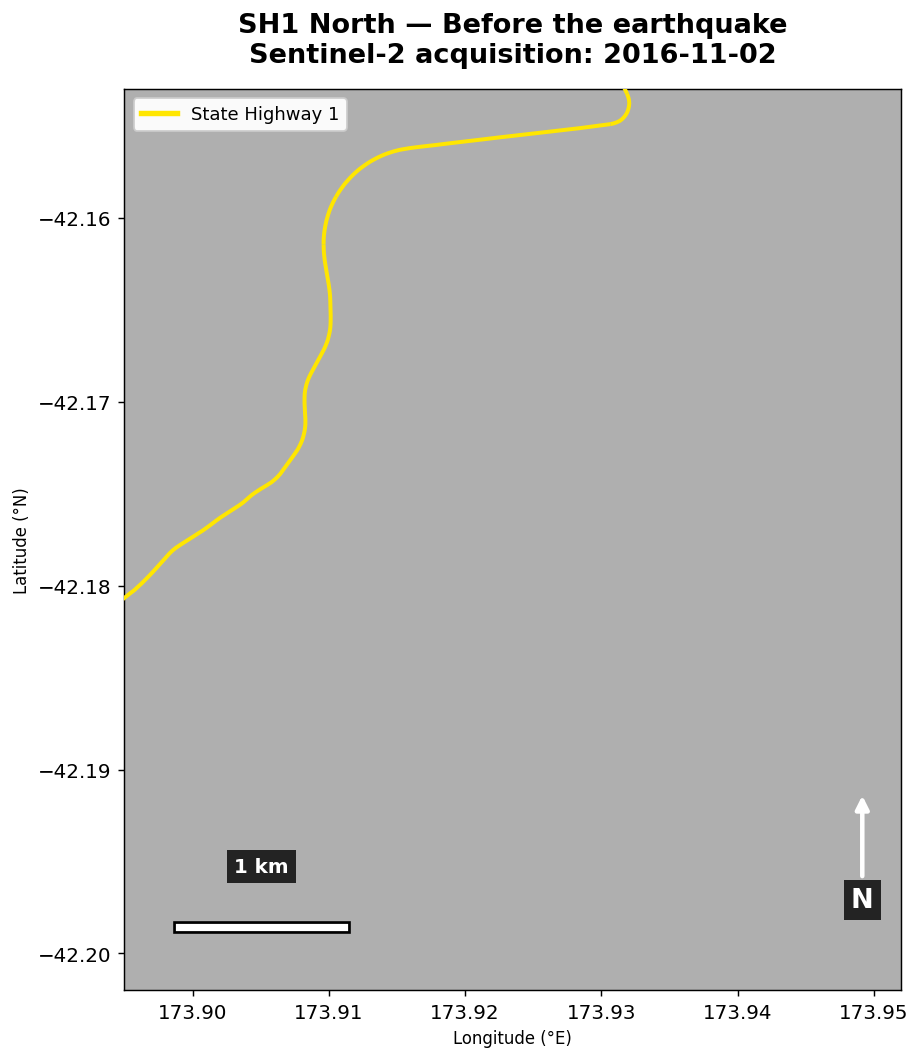

✅ Saved: 01_COASTAL_BEFORE.png


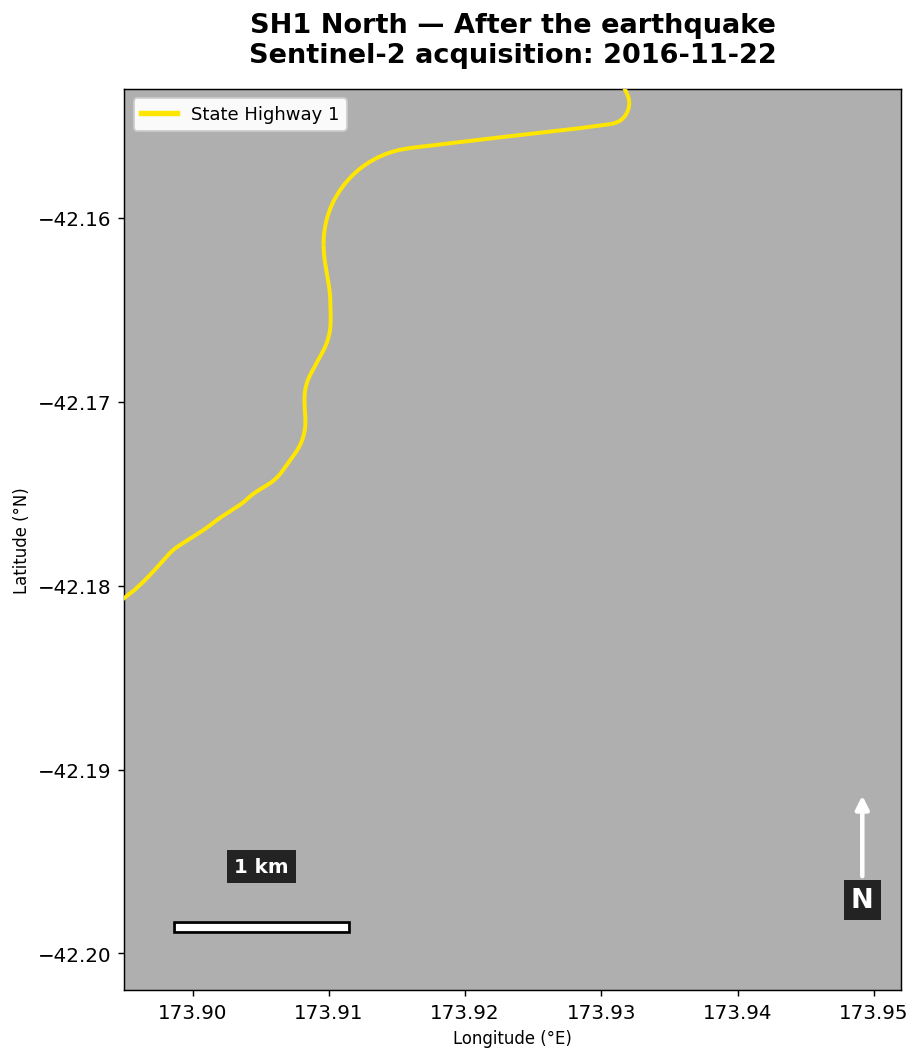

✅ Saved: 02_COASTAL_AFTER.png


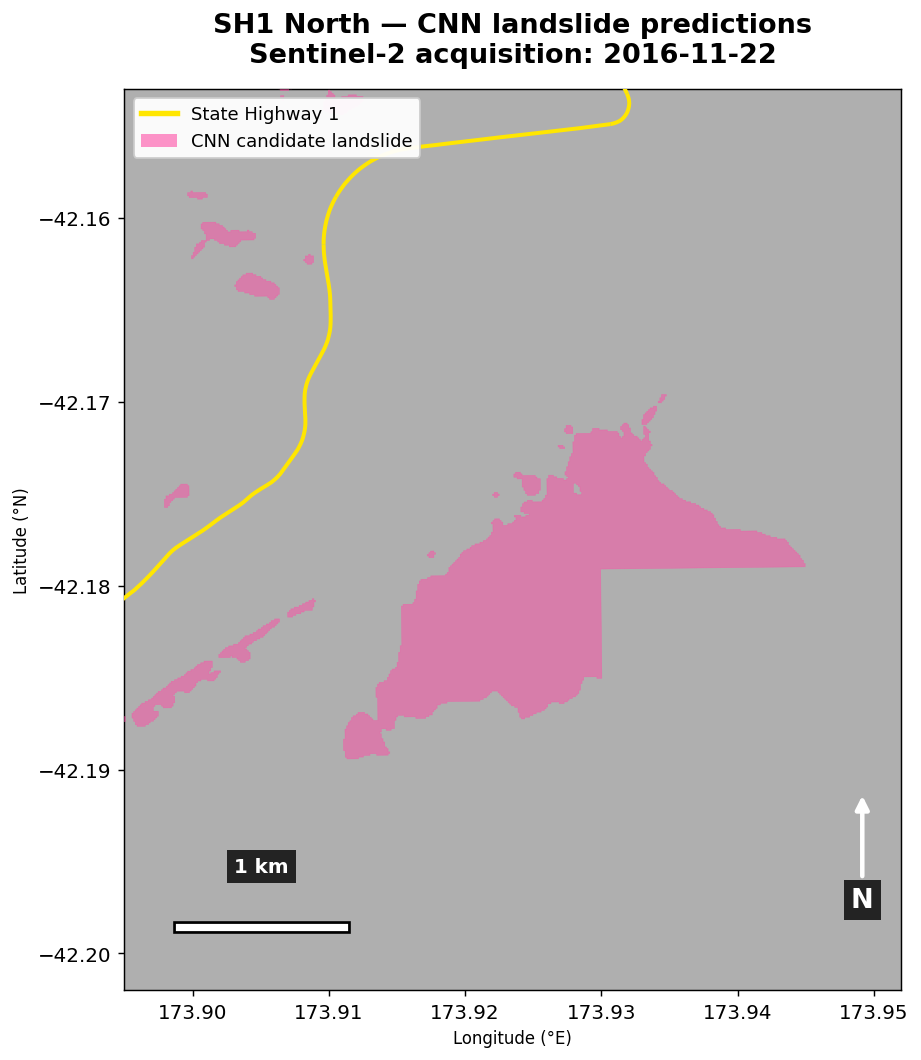

✅ Saved: 03_COASTAL_AFTER_WITH_CNN.png

✅ COASTAL CASE STUDY COMPLETE
Before date: 2016-11-02
After date: 2016-11-22

Figures saved in:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures/COASTAL_DIRECT_2016_SCENES

NO old backgrounds were reused.
NO QA60 cloud masking was applied.
NO CNN inference was performed.

Note: Images were selected using available historical coverage and a simple visual-quality screening heuristic. Bright pixels may still contain cloud, snow or exposed rock.


In [ ]:
# ==============================================================
# CELL 9 — SH1 NORTH COASTAL CASE STUDY
# DIRECT 2016 SENTINEL-2 SCENES — NO CLOUD MASK
#
# Outputs:
# 1. Before earthquake
# 2. After earthquake
# 3. After earthquake + CNN predictions
#
# NO old satellite images or caches
# NO QA60 masking
# NO CNN inference
# ==============================================================

from pathlib import Path
from io import BytesIO
import math
import requests
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

from PIL import Image
from shapely.geometry import box
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# --------------------------------------------------------------
# 1. PATHS
# --------------------------------------------------------------

EE_PROJECT = "just-terminus-512006-j1"

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

SH1_OUT = REPO / "outputs/kaikoura_full_coast_SH1"

OUT = (
    REPO
    / "outputs/final_presentation_figures"
    / "COASTAL_DIRECT_2016_SCENES"
)

OUT.mkdir(parents=True, exist_ok=True)

CNN_FILE = SH1_OUT / "03_predicted_landslides.geojson"
ROAD_FILE = SH1_OUT / "01_sh1_osm_current.geojson"

assert CNN_FILE.exists()
assert ROAD_FILE.exists()

# --------------------------------------------------------------
# 2. EXACT COASTAL AREA
# --------------------------------------------------------------

# Same offshore CNN candidate shown in your screenshots.

MINLON = 173.895
MAXLON = 173.952

MINLAT = -42.202
MAXLAT = -42.153

BOUNDS = (MINLON, MINLAT, MAXLON, MAXLAT)

ROI = ee.Geometry.Rectangle(
    [MINLON, MINLAT, MAXLON, MAXLAT]
)

WIDTH = 1400
HEIGHT = round(
    WIDTH * (MAXLAT - MINLAT) / (MAXLON - MINLON)
)

print("=" * 65)
print("DIRECT HISTORICAL SATELLITE ACQUISITION")
print("=" * 65)

print("Location: SH1 North coastline")
print("Image dimensions:", WIDTH, "×", HEIGHT)

# --------------------------------------------------------------
# 3. LOAD ORIGINAL CNN PREDICTIONS
# --------------------------------------------------------------

pred = gpd.read_file(CNN_FILE).to_crs("EPSG:4326")
roads = gpd.read_file(ROAD_FILE).to_crs("EPSG:4326")

view = box(*BOUNDS)

pred_view = pred[
    pred.geometry.intersects(view)
].copy()

roads_view = roads[
    roads.geometry.intersects(view)
].copy()

print("CNN polygons in view:", len(pred_view))

# --------------------------------------------------------------
# 4. EARTH ENGINE
# --------------------------------------------------------------

try:
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("✅ Earth Engine connected")

# --------------------------------------------------------------
# 5. DOWNLOAD ONE ACTUAL SATELLITE ACQUISITION
# --------------------------------------------------------------

def download_scene(image):

    # NO CLOUD MASK.
    #
    # Previous attempts masked the image and produced grey.
    #
    # Here we request actual Sentinel-2 RGB reflectance,
    # retaining the original pixels even where QA60 would
    # otherwise classify them as cloudy.

    rgb = (
        image
        .select(["B4", "B3", "B2"])
        .multiply(0.0001)
        .visualize(
            min=0.02,
            max=0.30,
            gamma=1.15
        )
    )

    url = rgb.getThumbURL({
        "region": ROI,
        "dimensions": f"{WIDTH}x{HEIGHT}",
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        url,
        timeout=120
    )

    response.raise_for_status()

    return Image.open(
        BytesIO(response.content)
    ).convert("RGBA")


# --------------------------------------------------------------
# 6. INSPECT ACTUAL IMAGE PIXELS
# --------------------------------------------------------------

def image_quality(image):

    arr = np.asarray(image)

    rgb = arr[:, :, :3].astype(np.float32)

    alpha = arr[:, :, 3]

    valid = alpha > 100

    coverage = float(valid.mean())

    if valid.sum() < 1000:
        return {
            "coverage": coverage,
            "white_fraction": 1.0,
            "variation": 0.0,
            "score": -999
        }

    pixels = rgb[valid]

    # Very bright, nearly neutral pixels can be
    # cloud/snow/bright terrain. This is only a
    # screening heuristic, NOT a cloud classifier.

    bright_neutral = (
        (pixels.min(axis=1) > 205)
        &
        (
            pixels.max(axis=1)
            - pixels.min(axis=1)
            < 35
        )
    )

    white_fraction = float(
        bright_neutral.mean()
    )

    variation = float(
        pixels.std(axis=0).mean()
    )

    score = (
        100 * coverage
        - 75 * white_fraction
        + 0.3 * min(variation, 60)
    )

    return {
        "coverage": coverage,
        "white_fraction": white_fraction,
        "variation": variation,
        "score": score
    }


# --------------------------------------------------------------
# 7. FIND REAL SCENES NEAR PREFERRED DATES
# --------------------------------------------------------------

def get_candidate_images(
    start,
    end,
    preferred_date,
    maximum=10
):

    collection = (
        ee.ImageCollection(
            "COPERNICUS/S2_HARMONIZED"
        )
        .filterBounds(ROI)
        .filterDate(start, end)
    )

    count = collection.size().getInfo()

    print("\nAvailable scenes:", count)

    assert count > 0, (
        f"No Sentinel-2 scenes between {start} and {end}"
    )

    preferred_ms = ee.Date(preferred_date).millis()

    def add_distance(image):

        difference = (
            ee.Number(
                image.get("system:time_start")
            )
            .subtract(preferred_ms)
            .abs()
        )

        return image.set(
            "days_from_preferred",
            difference
        )

    collection = (
        collection
        .map(add_distance)
        .sort("days_from_preferred")
    )

    n = min(count, maximum)

    scene_list = collection.toList(n)

    candidates = []

    for i in range(n):

        image = ee.Image(scene_list.get(i))

        metadata = image.toDictionary([
            "system:time_start",
            "CLOUDY_PIXEL_PERCENTAGE",
            "system:index"
        ]).getInfo()

        timestamp = metadata.get(
            "system:time_start"
        )

        if timestamp is None:
            continue

        date = (
            __import__("datetime")
            .datetime.fromtimestamp(
                timestamp / 1000,
                tz=__import__("datetime").timezone.utc
            )
            .strftime("%Y-%m-%d")
        )

        candidates.append({
            "image": image,
            "date": date,
            "cloud": metadata.get(
                "CLOUDY_PIXEL_PERCENTAGE"
            ),
            "id": metadata.get("system:index")
        })

    return candidates


# --------------------------------------------------------------
# 8. SELECT CLEAREST RENDERED IMAGE
# --------------------------------------------------------------

def select_historical_image(
    label,
    start,
    end,
    preferred_date
):

    print("\n" + "=" * 65)
    print(label)
    print("=" * 65)

    candidates = get_candidate_images(
        start,
        end,
        preferred_date
    )

    results = []

    for i, candidate in enumerate(candidates, 1):

        print(
            f"\n[{i}/{len(candidates)}] "
            f"Trying {candidate['date']}..."
        )

        try:

            image = download_scene(
                candidate["image"]
            )

            quality = image_quality(image)

            print(
                "Valid image coverage:",
                f"{quality['coverage']:.1%}"
            )

            print(
                "Bright neutral pixels:",
                f"{quality['white_fraction']:.1%}"
            )

            print(
                "Visible RGB variation:",
                f"{quality['variation']:.1f}"
            )

            results.append({
                **candidate,
                "rgb": image,
                "quality": quality
            })

            # Strong candidate — use immediately to
            # avoid unnecessary Earth Engine requests.
            #
            # High coverage and relatively few
            # cloud-like bright pixels.

            if (
                quality["coverage"] >= 0.95
                and quality["white_fraction"] <= 0.15
                and quality["variation"] >= 12
            ):
                print(
                    "✅ Suitable historical scene found"
                )
                break

        except Exception as exc:

            print(
                "Scene failed:",
                str(exc)[:180]
            )

    if not results:

        raise RuntimeError(
            f"No satellite imagery could be retrieved "
            f"for {label}."
        )

    results.sort(
        key=lambda r: r["quality"]["score"],
        reverse=True
    )

    best = results[0]

    q = best["quality"]

    # Refuse missing/flat imagery.
    if q["coverage"] < 0.85 or q["variation"] < 8:

        raise RuntimeError(
            f"{label}: No usable landscape image found. "
            f"Best date {best['date']}, "
            f"coverage {q['coverage']:.1%}, "
            f"variation {q['variation']:.1f}. "
            "Do not use a grey background."
        )

    print("\nSELECTED:", best["date"])
    print("Source scene:", best["id"])

    filename = (
        OUT
        / f"{label.replace(' ', '_')}_"
          f"{best['date']}_SATELLITE.png"
    )

    best["rgb"].save(filename)

    print("✅ Saved raw satellite:", filename.name)

    return best


# --------------------------------------------------------------
# 9. PRE-EARTHQUAKE IMAGE
# --------------------------------------------------------------

# Prioritise 2 November 2016, close to the earthquake.

before = select_historical_image(
    label="BEFORE EARTHQUAKE",
    start="2016-09-01",
    end="2016-11-14",
    preferred_date="2016-11-02"
)


# --------------------------------------------------------------
# 10. POST-EARTHQUAKE IMAGE
# --------------------------------------------------------------

# Prioritise 22 November 2016.
# This is eight days after the earthquake.

after = select_historical_image(
    label="AFTER EARTHQUAKE",
    start="2016-11-20",
    end="2016-12-31",
    preferred_date="2016-11-22"
)


# --------------------------------------------------------------
# 11. NORTH ARROW AND SCALE BAR
# --------------------------------------------------------------

def add_map_elements(ax):

    ax.annotate(
        "N",
        xy=(0.95, 0.22),
        xytext=(0.95, 0.10),
        xycoords="axes fraction",
        textcoords="axes fraction",
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color="white",
        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2.5
        ),
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8
        ),
        zorder=30
    )

    bar_lat = MINLAT + 0.07 * (MAXLAT - MINLAT)
    bar_lon = MINLON + 0.07 * (MAXLON - MINLON)

    km_in_lon = (
        1000
        / (
            111320
            * math.cos(math.radians(bar_lat))
        )
    )

    ax.plot(
        [bar_lon, bar_lon + km_in_lon],
        [bar_lat, bar_lat],
        color="black",
        linewidth=7,
        zorder=30
    )

    ax.plot(
        [bar_lon, bar_lon + km_in_lon],
        [bar_lat, bar_lat],
        color="white",
        linewidth=4,
        zorder=31
    )

    ax.text(
        bar_lon + km_in_lon / 2,
        bar_lat + 0.003,
        "1 km",
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8
        ),
        zorder=32
    )


# --------------------------------------------------------------
# 12. CREATE ACTUAL SATELLITE FIGURES
# --------------------------------------------------------------

def make_map(image, date, title, output, show_cnn=False):

    fig, ax = plt.subplots(
        figsize=(10, 9),
        facecolor="white"
    )

    ax.set_facecolor("#afafaf")

    ax.imshow(
        np.asarray(image),
        extent=BOUNDS,
        origin="upper",
        interpolation="nearest",
        zorder=0
    )

    if show_cnn and not pred_view.empty:

        pred_view.plot(
            ax=ax,
            facecolor="#ff4da6",
            edgecolor="#ff4da6",
            linewidth=0.3,
            alpha=0.50,
            zorder=3
        )

    if not roads_view.empty:

        roads_view.plot(
            ax=ax,
            color="#ffe600",
            linewidth=2.2,
            zorder=5
        )

    ax.set_xlim(MINLON, MAXLON)
    ax.set_ylim(MINLAT, MAXLAT)

    ax.set_aspect(
        1 / math.cos(
            math.radians(
                (MINLAT + MAXLAT) / 2
            )
        )
    )

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

    add_map_elements(ax)

    ax.set_title(
        f"SH1 North — {title}\n"
        f"Sentinel-2 acquisition: {date}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    legend = [
        Line2D(
            [], [],
            color="#ffe600",
            linewidth=3,
            label="State Highway 1"
        )
    ]

    if show_cnn:

        legend.append(
            Patch(
                facecolor="#ff4da6",
                alpha=0.6,
                label="CNN candidate landslide"
            )
        )

    ax.legend(
        handles=legend,
        loc="upper left",
        fontsize=10,
        framealpha=0.95
    )

    fig.savefig(
        output,
        dpi=250,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("✅ Saved:", output.name)


# --------------------------------------------------------------
# 13. EXPORT THREE SEPARATE FIGURES
# --------------------------------------------------------------

before_output = OUT / "01_COASTAL_BEFORE.png"

after_output = OUT / "02_COASTAL_AFTER.png"

cnn_output = OUT / "03_COASTAL_AFTER_WITH_CNN.png"


make_map(
    before["rgb"],
    before["date"],
    "Before the earthquake",
    before_output
)

make_map(
    after["rgb"],
    after["date"],
    "After the earthquake",
    after_output
)

make_map(
    after["rgb"],
    after["date"],
    "CNN landslide predictions",
    cnn_output,
    show_cnn=True
)


# --------------------------------------------------------------
# 14. FINISHED
# --------------------------------------------------------------

print("\n" + "=" * 65)
print("✅ COASTAL CASE STUDY COMPLETE")
print("=" * 65)

print("Before date:", before["date"])
print("After date:", after["date"])

print("\nFigures saved in:")
print(OUT)

print("\nNO old backgrounds were reused.")
print("NO QA60 cloud masking was applied.")
print("NO CNN inference was performed.")

print(
    "\nNote: Images were selected using available "
    "historical coverage and a simple visual-quality "
    "screening heuristic. Bright pixels may still "
    "contain cloud, snow or exposed rock."
)

In [ ]:
# ================================================================
# CELL 10 — FINAL ROUTE 70 ROAD DISRUPTION MAP
#
# FIX:
# Restores the ORIGINAL working Earth Engine RGB method.
# Preserves RGBA transparency instead of silently losing it.
# Rejects white/blank backgrounds before plotting.
#
# OUTPUT:
# ONE road-disruption figure with historical satellite imagery,
# coloured road segments, CNN polygons, legend, north arrow,
# and scale bar.
#
# NO GNS DATA.
# NO CNN INFERENCE.
# ================================================================

from pathlib import Path
from io import BytesIO
from PIL import Image
from IPython.display import display

import math
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

from pyproj import Transformer
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ================================================================
# 1. PATHS
# ================================================================

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

R70 = REPO / "outputs/kaikoura_route70"

OUT = (
    REPO
    / "outputs/final_presentation_figures"
    / "NZDF_EXPECTED_OUTPUT"
)

OUT.mkdir(parents=True, exist_ok=True)

ROAD_FILE = R70 / "01_route70_osm_current.geojson"
PRED_FILE = R70 / "03_predicted_landslides.geojson"
RISK_FILE = R70 / "04_SH1_road_assessment.geojson"

SATELLITE_FILE = (
    OUT / "ROUTE70_ACTUAL_2016_SATELLITE_FIXED.png"
)

MAP_FILE = (
    OUT / "ROUTE70_FINAL_ROAD_DISRUPTION_FIXED.png"
)

for path in [ROAD_FILE, PRED_FILE, RISK_FILE]:
    assert path.exists(), f"Missing: {path}"


# ================================================================
# 2. LOAD EXISTING RESULTS — NO GNS
# ================================================================

roads = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:4326")

pred = gpd.read_file(
    PRED_FILE
).to_crs("EPSG:4326")

risk = gpd.read_file(
    RISK_FILE
).to_crs("EPSG:4326")

assert not roads.empty
assert not risk.empty
assert "class" in risk.columns

print("=" * 65)
print("ROUTE 70 — ROAD DISRUPTION MAP")
print("=" * 65)

print("CNN polygons:", len(pred))
print("Road segments:", len(risk))
print("GNS data loaded: NO")


# ================================================================
# 3. MAP EXTENT
# ================================================================

# Same geographic approach as the successful old code.

minlon, minlat, maxlon, maxlat = roads.total_bounds

minlon -= 0.025
maxlon += 0.025

minlat -= 0.020
maxlat += 0.020

BOUNDS = (
    minlon,
    minlat,
    maxlon,
    maxlat
)

print("\nMap bounds:", BOUNDS)


# ================================================================
# 4. CONNECT TO EARTH ENGINE
# ================================================================

EE_PROJECT = "just-terminus-512006-j1"

try:
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("✅ Earth Engine connected")


# ================================================================
# 5. PREPARE HISTORICAL SATELLITE REGION
# ================================================================

region = ee.Geometry.Rectangle(
    [minlon, minlat, maxlon, maxlat]
)

# Original working method used geographic coordinates.
# Do not switch this back to EPSG:3857 or GeoTIFF export.

WIDTH = 1800

HEIGHT = round(
    WIDTH
    * (maxlat - minlat)
    / (maxlon - minlon)
)

print(
    "\nSatellite rendering dimensions:",
    WIDTH,
    "×",
    HEIGHT
)


# ================================================================
# 6. ORIGINAL WORKING CLOUD MASK
# ================================================================

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


# ================================================================
# 7. DOWNLOAD THE ACTUAL HISTORICAL RGB IMAGE
# ================================================================

def get_satellite_image(
    collection_name,
    start_date,
    end_date,
    apply_cloud_mask,
    satellite_type
):

    collection = (
        ee.ImageCollection(collection_name)
        .filterBounds(region)
        .filterDate(start_date, end_date)
    )

    count = collection.size().getInfo()

    print("Available scenes:", count)

    if count == 0:
        raise RuntimeError("No scenes available.")

    # --------------------------------------------
    # ORIGINAL WORKING MOSAIC METHOD
    # --------------------------------------------

    if satellite_type == "Sentinel-2":

        if apply_cloud_mask:
            collection = collection.map(mask_clouds)

        image = (
            collection
            .sort("CLOUDY_PIXEL_PERCENTAGE", False)
            .mosaic()
        )

        # Exactly the same reflectance conversion
        # and RGB visualisation as the old working code.

        rgb = (
            image
            .select(["B4", "B3", "B2"])
            .multiply(0.0001)
            .visualize(
                min=0.02,
                max=0.30,
                gamma=1.15
            )
        )

    else:

        # Historical Landsat 8 fallback.
        # Used only if Sentinel-2 imagery cannot
        # provide a visible background.

        image = (
            collection
            .sort("CLOUD_COVER", False)
            .mosaic()
        )

        rgb = (
            image
            .select(["B4", "B3", "B2"])
            .visualize(
                min=0.02,
                max=0.30,
                gamma=1.15
            )
        )

    # --------------------------------------------
    # CRITICAL: KEEP THE ORIGINAL RGBA IMAGE
    # --------------------------------------------

    # Do not unmask here.
    # Do not convert to RGB here.
    # Do not use the old broken PNG cache.
    #
    # The alpha channel tells us whether Earth
    # Engine actually returned visible pixels.

    thumb_url = rgb.getThumbURL({
        "region": region,
        "dimensions": f"{WIDTH}x{HEIGHT}",
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        thumb_url,
        timeout=180
    )

    response.raise_for_status()

    return Image.open(
        BytesIO(response.content)
    ).convert("RGBA")


# ================================================================
# 8. CHECK REAL LANDSCAPE VISIBILITY
# ================================================================

# We check:
# 1. Actual non-transparent pixels
# 2. Non-white, non-grey landscape colour
# 3. Satellite coverage along the road
#
# Counting unique RGB colours alone was insufficient
# in the earlier broken versions.


road_m = roads.to_crs("EPSG:2193")

road_line = road_m.geometry.iloc[0]

to_wgs = Transformer.from_crs(
    "EPSG:2193",
    "EPSG:4326",
    always_xy=True
)


def satellite_quality(image):

    arr = np.asarray(image)

    rgb = arr[:, :, :3].astype(np.int16)
    alpha = arr[:, :, 3]

    h, w = alpha.shape

    visible = alpha > 100

    colour_range = (
        rgb.max(axis=2) - rgb.min(axis=2)
    )

    brightness = rgb.mean(axis=2)

    # Genuine landscape should contain colour,
    # rather than being entirely white/grey.
    #
    # This is a visual-quality heuristic, not
    # a formal cloud classification.

    landscape = (
        visible
        & (brightness < 235)
        & (colour_range > 10)
    )

    visible_fraction = float(visible.mean())

    landscape_fraction = float(landscape.mean())

    # --------------------------------------------
    # Sample pixels along actual Route 70
    # --------------------------------------------

    road_samples = []

    for fraction in np.linspace(0, 1, 300):

        point = road_line.interpolate(
            road_line.length * fraction
        )

        lon, lat = to_wgs.transform(
            point.x,
            point.y
        )

        px = int(
            (lon - minlon)
            / (maxlon - minlon)
            * (w - 1)
        )

        py = int(
            (maxlat - lat)
            / (maxlat - minlat)
            * (h - 1)
        )

        if 0 <= px < w and 0 <= py < h:

            # Small neighbourhood reduces
            # sensitivity to exact pixel placement.

            y0 = max(0, py - 2)
            y1 = min(h, py + 3)

            x0 = max(0, px - 2)
            x1 = min(w, px + 3)

            patch = landscape[y0:y1, x0:x1]

            road_samples.append(
                bool(patch.mean() > 0.20)
            )

    road_fraction = (
        float(np.mean(road_samples))
        if road_samples else 0.0
    )

    print(
        f"Visible satellite coverage: "
        f"{visible_fraction:.1%}"
    )

    print(
        f"Visible landscape-colour coverage: "
        f"{landscape_fraction:.1%}"
    )

    print(
        f"Road with visible satellite landscape: "
        f"{road_fraction:.1%}"
    )

    passed = (
        visible_fraction >= 0.55
        and landscape_fraction >= 0.35
        and road_fraction >= 0.50
    )

    return passed


# ================================================================
# 9. SELECT A USABLE HISTORICAL BACKGROUND
# ================================================================

# Start with the exact old successful Sentinel-2
# approach. If its cloud mask removes too much data,
# try the original imagery without that mask.
#
# Use a wider historical window only if required.
#
# Landsat 8 is a last resort and will be labelled
# correctly rather than called Sentinel-2.

OPTIONS = [

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-20",
        "end": "2016-12-10",
        "mask": True
    },

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-20",
        "end": "2016-12-10",
        "mask": False
    },

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-14",
        "end": "2017-01-01",
        "mask": False
    },

    {
        "name": "Landsat 8",
        "collection": "LANDSAT/LC08/C02/T1_TOA",
        "start": "2016-11-14",
        "end": "2017-01-01",
        "mask": False
    }
]


background = None
selected_option = None

for option in OPTIONS:

    print("\n" + "=" * 60)

    print(
        "Trying:",
        option["name"],
        option["start"],
        "to",
        option["end"]
    )

    print(
        "Cloud mask:",
        option["mask"]
    )

    try:

        candidate = get_satellite_image(
            collection_name=option["collection"],
            start_date=option["start"],
            end_date=option["end"],
            apply_cloud_mask=option["mask"],
            satellite_type=option["name"]
        )

        print(
            "Actual downloaded image:",
            candidate.size,
            candidate.mode
        )

        passed = satellite_quality(candidate)

        if passed:

            background = candidate
            selected_option = option

            print(
                "\n✅ Satellite background passed "
                "the landscape visibility checks."
            )

            break

        print(
            "\n❌ Mostly blank or unsuitable "
            "satellite background."
        )

    except Exception as exc:

        print(
            "Image request failed:",
            str(exc)[:300]
        )


# ================================================================
# 10. STOP IF NO REAL SATELLITE BACKGROUND EXISTS
# ================================================================

if background is None:

    raise RuntimeError(
        "\nNo historical image passed the "
        "satellite-visibility checks.\n"
        "The road-disruption map has NOT been "
        "generated with another blank background.\n"
        "Check the printed coverage figures to "
        "identify whether the issue is missing "
        "satellite data or image rendering."
    )


# ================================================================
# 11. SAVE AND DISPLAY SATELLITE ALONE FIRST
# ================================================================

# This is the essential verification step.
#
# If this shows mountains and vegetation, then
# the figure has genuine satellite data BEFORE
# any road or CNN overlays are drawn.

background.save(SATELLITE_FILE)

print("\n" + "=" * 65)
print("SATELLITE BACKGROUND PREVIEW")
print("=" * 65)

print(
    "Selected source:",
    selected_option["name"]
)

print(
    "Period:",
    selected_option["start"],
    "to",
    selected_option["end"]
)

display(
    background.resize(
        (900, round(900 * HEIGHT / WIDTH))
    )
)

print("\n✅ Saved satellite preview:")
print(SATELLITE_FILE)


# ================================================================
# 12. ROAD CLASSIFICATIONS — ORIGINAL SAVED RESULTS
# ================================================================

ROAD_CLASSES = {

    "possible_impingement": {
        "colour": "#e31a1c",
        "label": "Possible impingement"
    },

    "inspection_priority": {
        "colour": "#ff9800",
        "label": "Inspection priority"
    },

    "no_detected_landslide_not_safe": {
        "colour": "#20a45c",
        "label": "No nearby detection"
    },

    "unknown_insufficient_imagery": {
        "colour": "#bdbdbd",
        "label": "Insufficient imagery"
    }
}

unexpected = (
    set(risk["class"].dropna().unique())
    - set(ROAD_CLASSES)
)

assert not unexpected, (
    f"Unexpected road classes: {unexpected}"
)


# ================================================================
# 13. ROAD LENGTH STATISTICS
# ================================================================

risk_m = risk.to_crs("EPSG:2193")

road_lengths = {}

for classification in ROAD_CLASSES:

    subset = risk_m[
        risk_m["class"] == classification
    ]

    road_lengths[classification] = (
        subset.geometry.length.sum() / 1000
    )


# ================================================================
# 14. MAKE FINAL MAP — SAME CRS AS OLD WORKING CODE
# ================================================================

fig = plt.figure(
    figsize=(16, 9),
    facecolor="white"
)

ax = fig.add_axes([
    0.015,
    0.08,
    0.78,
    0.82
])

legend_ax = fig.add_axes([
    0.81,
    0.22,
    0.18,
    0.61
])

legend_ax.axis("off")

# Neutral grey behind any genuinely missing pixels.

ax.set_facecolor("#afafaf")


# ================================================================
# 15. SATELLITE IMAGE — KEEP ORIGINAL RGBA
# ================================================================

# EXACT approach used by your successful old code:
#
# WGS84 image + WGS84 geographic extent.
#
# Do not replace with EPSG:3857 tile extents.
# Do not discard the alpha channel.

ax.imshow(
    np.asarray(background),
    extent=(
        minlon,
        maxlon,
        minlat,
        maxlat
    ),
    origin="upper",
    interpolation="nearest",
    zorder=0
)


# ================================================================
# 16. CNN LANDSLIDE POLYGONS
# ================================================================

if not pred.empty:

    pred.plot(
        ax=ax,
        facecolor="#ff4da6",
        edgecolor="#ff4da6",
        linewidth=0.2,
        alpha=0.27,
        zorder=3
    )


# ================================================================
# 17. ROAD INSPECTION PRIORITIES
# ================================================================

risk.plot(
    ax=ax,
    color="#111111",
    linewidth=5,
    zorder=7
)

for classification, style in ROAD_CLASSES.items():

    subset = risk[
        risk["class"] == classification
    ]

    if subset.empty:
        continue

    subset.plot(
        ax=ax,
        color=style["colour"],
        linewidth=3.2,
        zorder=8
    )


# ================================================================
# 18. MAP EXTENT
# ================================================================

ax.set_xlim(minlon, maxlon)
ax.set_ylim(minlat, maxlat)

ax.set_aspect(
    1 / math.cos(
        math.radians(
            (minlat + maxlat) / 2
        )
    )
)

ax.axis("off")


# ================================================================
# 19. NORTH ARROW
# ================================================================

ax.annotate(
    "N",
    xy=(0.95, 0.23),
    xytext=(0.95, 0.10),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontsize=15,
    fontweight="bold",
    color="white",
    arrowprops=dict(
        arrowstyle="-|>",
        color="white",
        linewidth=2.5
    ),
    bbox=dict(
        facecolor="black",
        edgecolor="none",
        alpha=0.8,
        pad=3
    ),
    zorder=30
)


# ================================================================
# 20. 10 KM SCALE BAR
# ================================================================

bar_lat = minlat + 0.07 * (
    maxlat - minlat
)

bar_lon = minlon + 0.06 * (
    maxlon - minlon
)

scale_lon = (
    10000
    / (
        111320
        * math.cos(math.radians(bar_lat))
    )
)

ax.plot(
    [bar_lon, bar_lon + scale_lon],
    [bar_lat, bar_lat],
    color="black",
    linewidth=8,
    zorder=30
)

ax.plot(
    [bar_lon, bar_lon + scale_lon],
    [bar_lat, bar_lat],
    color="white",
    linewidth=4,
    zorder=31
)

ax.text(
    bar_lon + scale_lon / 2,
    bar_lat + 0.012,
    "10 km",
    color="white",
    fontsize=12,
    fontweight="bold",
    ha="center",
    bbox=dict(
        facecolor="black",
        edgecolor="none",
        alpha=0.8
    ),
    zorder=32
)


# ================================================================
# 21. SIMPLE LEGEND ONLY
# ================================================================

handles = []

for classification, style in ROAD_CLASSES.items():

    handles.append(
        Line2D(
            [0], [0],
            color=style["colour"],
            linewidth=5,
            label=(
                f"{style['label']}\n"
                f"{road_lengths[classification]:.1f} km"
            )
        )
    )

handles.append(
    Patch(
        facecolor="#ff4da6",
        edgecolor="#ff4da6",
        alpha=0.45,
        label="CNN landslide candidates"
    )
)

legend_ax.legend(
    handles=handles,
    loc="center left",
    fontsize=12,
    labelspacing=1.5,
    frameon=False,
    handlelength=2.5
)


# ================================================================
# 22. TITLE AND MINIMAL FOOTER
# ================================================================

fig.suptitle(
    "Inland Route 70 — Potential Road Disruption",
    fontsize=23,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5,
    0.025,
    (
        f"Historical {selected_option['name']} imagery "
        f"({selected_option['start']} to "
        f"{selected_option['end']}, end exclusive). "
        "CNN-derived inspection priorities; "
        "not confirmed road closures."
    ),
    ha="center",
    fontsize=10,
    color="#444444"
)


# ================================================================
# 23. SAVE FINAL FIGURE
# ================================================================

fig.savefig(
    MAP_FILE,
    dpi=240,
    facecolor="white"
)

plt.show()
plt.close(fig)


# ================================================================
# 24. DONE
# ================================================================

print("\n" + "=" * 65)
print("FINAL ROAD DISRUPTION MAP COMPLETE")
print("=" * 65)

print("\nSatellite-only image:")
print(SATELLITE_FILE)

print("\nFinal map:")
print(MAP_FILE)

print("\nSatellite source:")
print(selected_option["name"])

print("\n✅ Existing road classifications")
print("✅ Existing CNN predictions")
print("✅ No GNS data")
print("✅ No CNN inference")

Output hidden; open in https://colab.research.google.com to view.

SH1 north and south

In [ ]:
# ================================================================
# CELL 11 — SH1 NORTH + SH1 SOUTH ROAD DISRUPTION MAPS
#
# SAME WORKING METHOD AS THE FINAL ROUTE 70 CELL
#
# OUTPUTS:
#   1. SH1 NORTH — satellite + road disruption
#   2. SH1 SOUTH — satellite + road disruption
#
# Includes:
#   - Actual historical 2016 satellite imagery
#   - Original CNN landslide predictions
#   - Existing road classifications
#   - Red / orange / green / grey road segments
#   - Pink CNN polygons
#   - Simple legend
#   - North arrow
#   - 5 km scale bar
#
# NO GNS DATA
# NO CNN INFERENCE
# NO MODEL RETRAINING
# ================================================================

from pathlib import Path
from io import BytesIO

import json
import math
import requests

import ee
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display
from shapely.geometry import box
from pyproj import Transformer
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ================================================================
# 1. FILE PATHS
# ================================================================

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

SH1 = REPO / "outputs/kaikoura_full_coast_SH1"

OUT = (
    REPO
    / "outputs/final_presentation_figures"
    / "NZDF_EXPECTED_OUTPUT"
)

OUT.mkdir(parents=True, exist_ok=True)

ROAD_FILE = SH1 / "01_sh1_osm_current.geojson"
PRED_FILE = SH1 / "03_predicted_landslides.geojson"
RISK_FILE = SH1 / "04_SH1_road_assessment.geojson"

for path in [ROAD_FILE, PRED_FILE, RISK_FILE]:
    assert path.exists(), f"Missing file: {path}"

print("=" * 70)
print("SH1 NORTH + SOUTH — ROAD DISRUPTION MAPS")
print("=" * 70)


# ================================================================
# 2. LOAD EXISTING CNN AND ROAD DATA
# ================================================================

roads_all = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:4326")

pred_all = gpd.read_file(
    PRED_FILE
).to_crs("EPSG:4326")

risk_all = gpd.read_file(
    RISK_FILE
).to_crs("EPSG:4326")

assert not roads_all.empty
assert not pred_all.empty
assert not risk_all.empty
assert "class" in risk_all.columns

print("\nExisting data:")
print("Road features:", len(roads_all))
print("CNN polygons:", len(pred_all))
print("Assessed road segments:", len(risk_all))

print("\nGNS data loaded: NO")


# ================================================================
# 3. SPLIT SH1 NORTH AND SOUTH
# ================================================================

# Same approximate Kaikoura boundary as the
# previous three-corridor comparison.

DIVIDER_LAT = -42.40

NORTH_REGION = box(
    172.0,
    DIVIDER_LAT,
    175.0,
    -41.0
)

SOUTH_REGION = box(
    172.0,
    -44.0,
    175.0,
    DIVIDER_LAT
)


def clip_to_region(gdf, region):

    result = gdf.copy()

    result["geometry"] = (
        result.geometry.intersection(region)
    )

    result = result[
        result.geometry.notna()
        & ~result.geometry.is_empty
    ].copy()

    return result


CORRIDORS = {

    "SH1 North": {
        "road": clip_to_region(
            roads_all,
            NORTH_REGION
        ),

        "pred": clip_to_region(
            pred_all,
            NORTH_REGION
        ),

        "risk": clip_to_region(
            risk_all,
            NORTH_REGION
        )
    },

    "SH1 South": {
        "road": clip_to_region(
            roads_all,
            SOUTH_REGION
        ),

        "pred": clip_to_region(
            pred_all,
            SOUTH_REGION
        ),

        "risk": clip_to_region(
            risk_all,
            SOUTH_REGION
        )
    }
}

for name, data in CORRIDORS.items():

    assert not data["road"].empty, (
        f"No road geometry for {name}"
    )

    assert not data["risk"].empty, (
        f"No road assessment for {name}"
    )

    print(f"\n{name}")
    print("CNN polygons:", len(data["pred"]))
    print("Road segments:", len(data["risk"]))


# ================================================================
# 4. CONNECT GOOGLE EARTH ENGINE
# ================================================================

EE_PROJECT = "just-terminus-512006-j1"

try:

    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:

    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("\n✅ Google Earth Engine connected")


# ================================================================
# 5. ROAD CLASSIFICATION COLOURS
# ================================================================

ROAD_CLASSES = {

    "possible_impingement": {
        "colour": "#e31a1c",
        "label": "Possible impingement"
    },

    "inspection_priority": {
        "colour": "#ff9800",
        "label": "Inspection priority"
    },

    "no_detected_landslide_not_safe": {
        "colour": "#20a45c",
        "label": "No nearby detection"
    },

    "unknown_insufficient_imagery": {
        "colour": "#bdbdbd",
        "label": "Insufficient imagery"
    }
}

unknown = (
    set(risk_all["class"].dropna().unique())
    - set(ROAD_CLASSES)
)

assert not unknown, (
    f"Unexpected road classifications: {unknown}"
)


# ================================================================
# 6. ORIGINAL WORKING SENTINEL-2 CLOUD MASK
# ================================================================

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


# ================================================================
# 7. PREPARE HISTORICAL SATELLITE BACKGROUND
# ================================================================

def download_satellite(
    bounds,
    collection_name,
    start,
    end,
    use_mask,
    source_name
):

    minlon, minlat, maxlon, maxlat = bounds

    region = ee.Geometry.Rectangle([
        minlon,
        minlat,
        maxlon,
        maxlat
    ])

    collection = (
        ee.ImageCollection(collection_name)
        .filterBounds(region)
        .filterDate(start, end)
    )

    count = collection.size().getInfo()

    print("Available historical scenes:", count)

    if count == 0:
        raise RuntimeError("No scenes available.")

    if source_name == "Sentinel-2":

        if use_mask:
            collection = collection.map(mask_clouds)

        mosaic = (
            collection
            .sort(
                "CLOUDY_PIXEL_PERCENTAGE",
                False
            )
            .mosaic()
        )

        # EXACT WORKING RGB METHOD:
        # B4 red, B3 green, B2 blue.

        rgb = (
            mosaic
            .select(["B4", "B3", "B2"])
            .multiply(0.0001)
            .visualize(
                min=0.02,
                max=0.30,
                gamma=1.15
            )
        )

    else:

        # Historical Landsat 8 fallback.
        # Only used if Sentinel-2 cannot provide
        # sufficiently visible imagery.

        mosaic = (
            collection
            .sort("CLOUD_COVER", False)
            .mosaic()
        )

        rgb = (
            mosaic
            .select(["B4", "B3", "B2"])
            .visualize(
                min=0.02,
                max=0.30,
                gamma=1.15
            )
        )

    width = 1800

    height = round(
        width
        * (maxlat - minlat)
        / (maxlon - minlon)
    )

    print(
        "Downloading satellite:",
        width,
        "×",
        height
    )

    # IMPORTANT:
    #
    # Original successful method:
    # EPSG:4326 thumbnail.
    #
    # Do not convert to RGB or fill missing pixels
    # before checking the alpha channel.

    url = rgb.getThumbURL({

        "region": region,

        "dimensions": f"{width}x{height}",

        "crs": "EPSG:4326",

        "format": "png"

    })

    response = requests.get(
        url,
        timeout=180
    )

    response.raise_for_status()

    return Image.open(
        BytesIO(response.content)
    ).convert("RGBA")


# ================================================================
# 8. SATELLITE VISIBILITY CHECK
# ================================================================

def satellite_quality(
    image,
    bounds,
    road
):

    """
    Reject missing or nearly blank satellite imagery.

    Check actual RGB/alpha coverage AND road locations,
    rather than merely checking image dimensions
    or counting unique colours.
    """

    arr = np.asarray(image)

    rgb = arr[:, :, :3].astype(np.int16)
    alpha = arr[:, :, 3]

    height, width = alpha.shape

    visible = alpha > 100

    brightness = rgb.mean(axis=2)

    colour_range = (
        rgb.max(axis=2)
        - rgb.min(axis=2)
    )

    landscape = (
        visible
        & (brightness < 235)
        & (colour_range > 10)
    )

    visible_fraction = float(
        visible.mean()
    )

    landscape_fraction = float(
        landscape.mean()
    )

    # --------------------------------------------------------
    # Sample the ACTUAL road across all its geometries.
    # Do not sample only the first road feature.
    # --------------------------------------------------------

    road_m = road.to_crs("EPSG:2193")

    geometries = [
        geom
        for geom in road_m.geometry
        if (
            geom is not None
            and not geom.is_empty
            and geom.length > 0
        )
    ]

    if not geometries:
        raise RuntimeError(
            "No valid road geometry for quality check."
        )

    lengths = np.asarray([
        geom.length for geom in geometries
    ])

    cumulative = np.cumsum(lengths)

    total_length = float(cumulative[-1])

    to_wgs = Transformer.from_crs(
        "EPSG:2193",
        "EPSG:4326",
        always_xy=True
    )

    minlon, minlat, maxlon, maxlat = bounds

    samples = []

    for distance in np.linspace(
        0,
        total_length,
        350,
        endpoint=False
    ):

        index = int(
            np.searchsorted(
                cumulative,
                distance,
                side="right"
            )
        )

        index = min(
            index,
            len(geometries) - 1
        )

        previous = (
            cumulative[index - 1]
            if index > 0 else 0
        )

        point = geometries[index].interpolate(
            float(distance - previous)
        )

        lon, lat = to_wgs.transform(
            point.x,
            point.y
        )

        px = int(
            (lon - minlon)
            / (maxlon - minlon)
            * (width - 1)
        )

        py = int(
            (maxlat - lat)
            / (maxlat - minlat)
            * (height - 1)
        )

        if not (
            0 <= px < width
            and 0 <= py < height
        ):
            continue

        # Small pixel neighbourhood around the road.

        patch = landscape[
            max(0, py - 2):min(height, py + 3),
            max(0, px - 2):min(width, px + 3)
        ]

        samples.append(
            bool(patch.mean() > 0.20)
        )

    road_fraction = (
        float(np.mean(samples))
        if samples else 0
    )

    print(
        "Visible satellite pixels:",
        f"{visible_fraction:.1%}"
    )

    print(
        "Landscape-colour pixels:",
        f"{landscape_fraction:.1%}"
    )

    print(
        "Road with visible landscape:",
        f"{road_fraction:.1%}"
    )

    passed = (
        visible_fraction >= 0.55
        and landscape_fraction >= 0.35
        and road_fraction >= 0.50
    )

    return passed


# ================================================================
# 9. HISTORICAL SATELLITE OPTIONS
# ================================================================

# Same options as the successful Route 70 cell.
#
# Sentinel-2 is preferred.
# Landsat 8 is a historical fallback only.
#
# The map will identify whichever source is used.

SATELLITE_OPTIONS = [

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-20",
        "end": "2016-12-10",
        "mask": True
    },

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-20",
        "end": "2016-12-10",
        "mask": False
    },

    {
        "name": "Sentinel-2",
        "collection": "COPERNICUS/S2_HARMONIZED",
        "start": "2016-11-14",
        "end": "2017-01-01",
        "mask": False
    },

    {
        "name": "Landsat 8",
        "collection": "LANDSAT/LC08/C02/T1_TOA",
        "start": "2016-11-14",
        "end": "2017-01-01",
        "mask": False
    }
]


# ================================================================
# 10. NORTH ARROW AND SCALE BAR
# ================================================================

def add_map_elements(ax, bounds):

    minlon, minlat, maxlon, maxlat = bounds

    # North arrow — bottom right.

    ax.annotate(
        "N",

        xy=(0.95, 0.23),
        xytext=(0.95, 0.10),

        xycoords="axes fraction",
        textcoords="axes fraction",

        ha="center",

        fontsize=16,
        fontweight="bold",

        color="white",

        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2.5
        ),

        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8,
            pad=3
        ),

        zorder=30
    )

    # 5 km scale bar.

    scale_km = 5

    bar_lat = (
        minlat
        + 0.07 * (maxlat - minlat)
    )

    bar_lon = (
        minlon
        + 0.06 * (maxlon - minlon)
    )

    scale_lon = (
        scale_km * 1000
        / (
            111320
            * math.cos(
                math.radians(bar_lat)
            )
        )
    )

    ax.plot(
        [bar_lon, bar_lon + scale_lon],
        [bar_lat, bar_lat],
        color="black",
        linewidth=8,
        zorder=30
    )

    ax.plot(
        [bar_lon, bar_lon + scale_lon],
        [bar_lat, bar_lat],
        color="white",
        linewidth=4,
        zorder=31
    )

    ax.text(
        bar_lon + scale_lon / 2,
        bar_lat + 0.012,
        "5 km",
        fontsize=12,
        fontweight="bold",
        color="white",
        ha="center",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8
        ),
        zorder=32
    )


# ================================================================
# 11. CREATE ONE ROAD DISRUPTION MAP
# ================================================================

def create_road_map(
    corridor_name,
    data
):

    print("\n" + "=" * 70)
    print("PROCESSING:", corridor_name)
    print("=" * 70)

    road = data["road"]
    pred = data["pred"]
    risk = data["risk"]

    safe_name = (
        corridor_name
        .upper()
        .replace(" ", "_")
    )

    # --------------------------------------------------------
    # Geographic map extent.
    # --------------------------------------------------------

    minlon, minlat, maxlon, maxlat = (
        road.total_bounds
    )

    minlon -= 0.025
    maxlon += 0.025

    minlat -= 0.020
    maxlat += 0.020

    bounds = (
        minlon,
        minlat,
        maxlon,
        maxlat
    )

    # --------------------------------------------------------
    # Retrieve a satellite background with actual terrain.
    # --------------------------------------------------------

    satellite_file = (
        OUT
        / f"{safe_name}_2016_SATELLITE.png"
    )

    satellite_metadata_file = (
        OUT
        / f"{safe_name}_SATELLITE_METADATA.json"
    )

    background = None
    selected = None

    # Reuse only a previously VERIFIED successful image.
    # Never reuse images from the earlier broken cells.

    if (
        satellite_file.exists()
        and satellite_metadata_file.exists()
    ):

        try:

            metadata = json.loads(
                satellite_metadata_file.read_text()
            )

            cached = Image.open(
                satellite_file
            ).convert("RGBA")

            same_bounds = np.allclose(
                metadata["bounds"],
                bounds,
                atol=1e-7,
                rtol=0
            )

            if same_bounds and satellite_quality(
                cached,
                bounds,
                road
            ):

                background = cached

                selected = metadata["source"]

                print(
                    "✅ Reusing verified satellite image"
                )

        except Exception as exc:

            print(
                "Cached image unsuitable:",
                str(exc)[:150]
            )

    # --------------------------------------------------------
    # Download if no verified satellite is cached.
    # --------------------------------------------------------

    if background is None:

        for option in SATELLITE_OPTIONS:

            print("\nTrying historical imagery:")

            print(
                option["name"],
                option["start"],
                "to",
                option["end"]
            )

            print(
                "Cloud mask:",
                option["mask"]
            )

            try:

                candidate = download_satellite(
                    bounds=bounds,
                    collection_name=option["collection"],
                    start=option["start"],
                    end=option["end"],
                    use_mask=option["mask"],
                    source_name=option["name"]
                )

                print(
                    "Actual image:",
                    candidate.size,
                    candidate.mode
                )

                passed = satellite_quality(
                    candidate,
                    bounds,
                    road
                )

                if passed:

                    background = candidate
                    selected = option

                    print(
                        "✅ Satellite landscape visible"
                    )

                    break

                print(
                    "❌ Insufficient landscape coverage."
                )

            except Exception as exc:

                print(
                    "Satellite request failed:",
                    str(exc)[:250]
                )

    # --------------------------------------------------------
    # Stop if background is unusable.
    # --------------------------------------------------------

    if background is None:

        raise RuntimeError(
            f"\n{corridor_name}: No satellite "
            "background passed the visibility check.\n"
            "No blank road-disruption map was saved."
        )

    # --------------------------------------------------------
    # Save the verified satellite background.
    # --------------------------------------------------------

    background.save(
        satellite_file
    )

    satellite_metadata_file.write_text(
        json.dumps(
            {
                "bounds": list(bounds),
                "source": selected,
                "year": 2016
            },
            indent=2
        )
    )

    print("\nSATELLITE BACKGROUND PREVIEW")

    display(
        background.resize(
            (
                650,
                round(
                    650
                    * background.height
                    / background.width
                )
            )
        )
    )

    # --------------------------------------------------------
    # Road lengths for the legend.
    # --------------------------------------------------------

    risk_m = risk.to_crs("EPSG:2193")

    road_lengths = {}

    for classification in ROAD_CLASSES:

        subset = risk_m[
            risk_m["class"] == classification
        ]

        road_lengths[classification] = (
            subset.geometry.length.sum() / 1000
        )

    # --------------------------------------------------------
    # Create the figure.
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(16, 9),
        facecolor="white"
    )

    ax = fig.add_axes([
        0.025,
        0.075,
        0.76,
        0.82
    ])

    legend_ax = fig.add_axes([
        0.805,
        0.23,
        0.19,
        0.59
    ])

    legend_ax.axis("off")

    ax.set_facecolor("#afafaf")

    # --------------------------------------------------------
    # REAL HISTORICAL SATELLITE BACKGROUND
    # --------------------------------------------------------

    ax.imshow(
        np.asarray(background),

        extent=(
            minlon,
            maxlon,
            minlat,
            maxlat
        ),

        origin="upper",
        interpolation="nearest",
        zorder=0
    )

    # --------------------------------------------------------
    # ORIGINAL CNN LANDSLIDE POLYGONS
    # --------------------------------------------------------

    if not pred.empty:

        pred.plot(
            ax=ax,
            facecolor="#ff4da6",
            edgecolor="#ff4da6",
            linewidth=0.2,
            alpha=0.27,
            zorder=3
        )

    # --------------------------------------------------------
    # COLOURED ROAD CLASSIFICATIONS
    # --------------------------------------------------------

    # Dark backing for contrast.

    risk.plot(
        ax=ax,
        color="#111111",
        linewidth=5,
        zorder=7
    )

    for classification, style in ROAD_CLASSES.items():

        subset = risk[
            risk["class"] == classification
        ]

        if subset.empty:
            continue

        subset.plot(
            ax=ax,
            color=style["colour"],
            linewidth=3.2,
            zorder=8
        )

    # --------------------------------------------------------
    # MAP EXTENT
    # --------------------------------------------------------

    ax.set_xlim(minlon, maxlon)
    ax.set_ylim(minlat, maxlat)

    ax.set_aspect(
        1 / math.cos(
            math.radians(
                (minlat + maxlat) / 2
            )
        )
    )

    ax.axis("off")

    add_map_elements(
        ax,
        bounds
    )

    # --------------------------------------------------------
    # LEGEND ONLY
    # --------------------------------------------------------

    handles = []

    for classification, style in ROAD_CLASSES.items():

        length = road_lengths[classification]

        handles.append(
            Line2D(
                [0], [0],
                color=style["colour"],
                linewidth=5,
                label=(
                    f"{style['label']}\n"
                    f"{length:.1f} km"
                )
            )
        )

    handles.append(
        Patch(
            facecolor="#ff4da6",
            edgecolor="#ff4da6",
            alpha=0.45,
            label="CNN landslide candidates"
        )
    )

    legend_ax.legend(
        handles=handles,
        loc="center left",
        fontsize=12,
        labelspacing=1.5,
        frameon=False,
        handlelength=2.5
    )

    # --------------------------------------------------------
    # TITLE AND FOOTER
    # --------------------------------------------------------

    fig.suptitle(
        f"{corridor_name} — Potential Road Disruption",
        fontsize=23,
        fontweight="bold",
        y=0.96
    )

    fig.text(
        0.5,
        0.025,
        (
            f"Historical {selected['name']} imagery: "
            f"{selected['start']} to "
            f"{selected['end']} (end exclusive). "
            "CNN-derived inspection priorities; "
            "not confirmed road closures."
        ),
        ha="center",
        fontsize=10,
        color="#444444"
    )

    # --------------------------------------------------------
    # SAVE ONE INDIVIDUAL FIGURE
    # --------------------------------------------------------

    output_file = (
        OUT
        / f"{safe_name}_ROAD_DISRUPTION_WITH_SATELLITE.png"
    )

    fig.savefig(
        output_file,
        dpi=240,
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print("\n✅ Saved:", output_file)

    return output_file


# ================================================================
# 12. GENERATE BOTH SH1 MAPS
# ================================================================

OUTPUTS = []

for corridor_name, data in CORRIDORS.items():

    result = create_road_map(
        corridor_name,
        data
    )

    OUTPUTS.append(result)


# ================================================================
# 13. FINISHED
# ================================================================

print("\n" + "=" * 70)
print("✅ BOTH SH1 ROAD DISRUPTION MAPS COMPLETE")
print("=" * 70)

print("\nGenerated figures:")

for output in OUTPUTS:
    print("✅", output)

print("\n✅ Historical satellite imagery")
print("✅ Existing CNN predictions")
print("✅ Existing road assessments")
print("✅ No GNS data")
print("✅ No CNN inference")

Output hidden; open in https://colab.research.google.com to view.

CNN DEMONSTRATION — LANDSLIDE NEAR ROUTE 70

Loaded:
CNN polygons: 642
Road segments: 390
Red road segments: 38
Orange road segments: 48

✅ Existing CNN-based road priorities loaded
✅ No GNS data used

Saved CNN tiles: 58

Evaluating CNN tiles near Route 70...

BEST ROAD-RELATED CNN TILES
C_633_2069 | Red road: 2520 m | CNN ≤100 m: 123626 m² | CNN ≤30 m: 37377 m²
C_633_2070 | Red road: 2195 m | CNN ≤100 m: 119908 m² | CNN ≤30 m: 35333 m²
C_634_2070 | Red road: 1496 m | CNN ≤100 m: 79129 m² | CNN ≤30 m: 22098 m²
C_626_2062 | Red road: 1597 m | CNN ≤100 m: 92462 m² | CNN ≤30 m: 18617 m²
C_627_2062 | Red road: 1397 m | CNN ≤100 m: 83101 m² | CNN ≤30 m: 17533 m²
C_634_2069 | Red road: 1447 m | CNN ≤100 m: 77450 m² | CNN ≤30 m: 22043 m²
C_628_2064 | Red road: 1197 m | CNN ≤100 m: 75304 m² | CNN ≤30 m: 14174 m²
C_627_2064 | Red road: 917 m | CNN ≤100 m: 50502 m² | CNN ≤30 m: 7476 m²
C_636_2072 | Red road: 798 m | CNN ≤100 m: 40776 m² | CNN ≤30 m: 6429 m²
C_626_2061 | Red road: 544 m | CNN ≤1

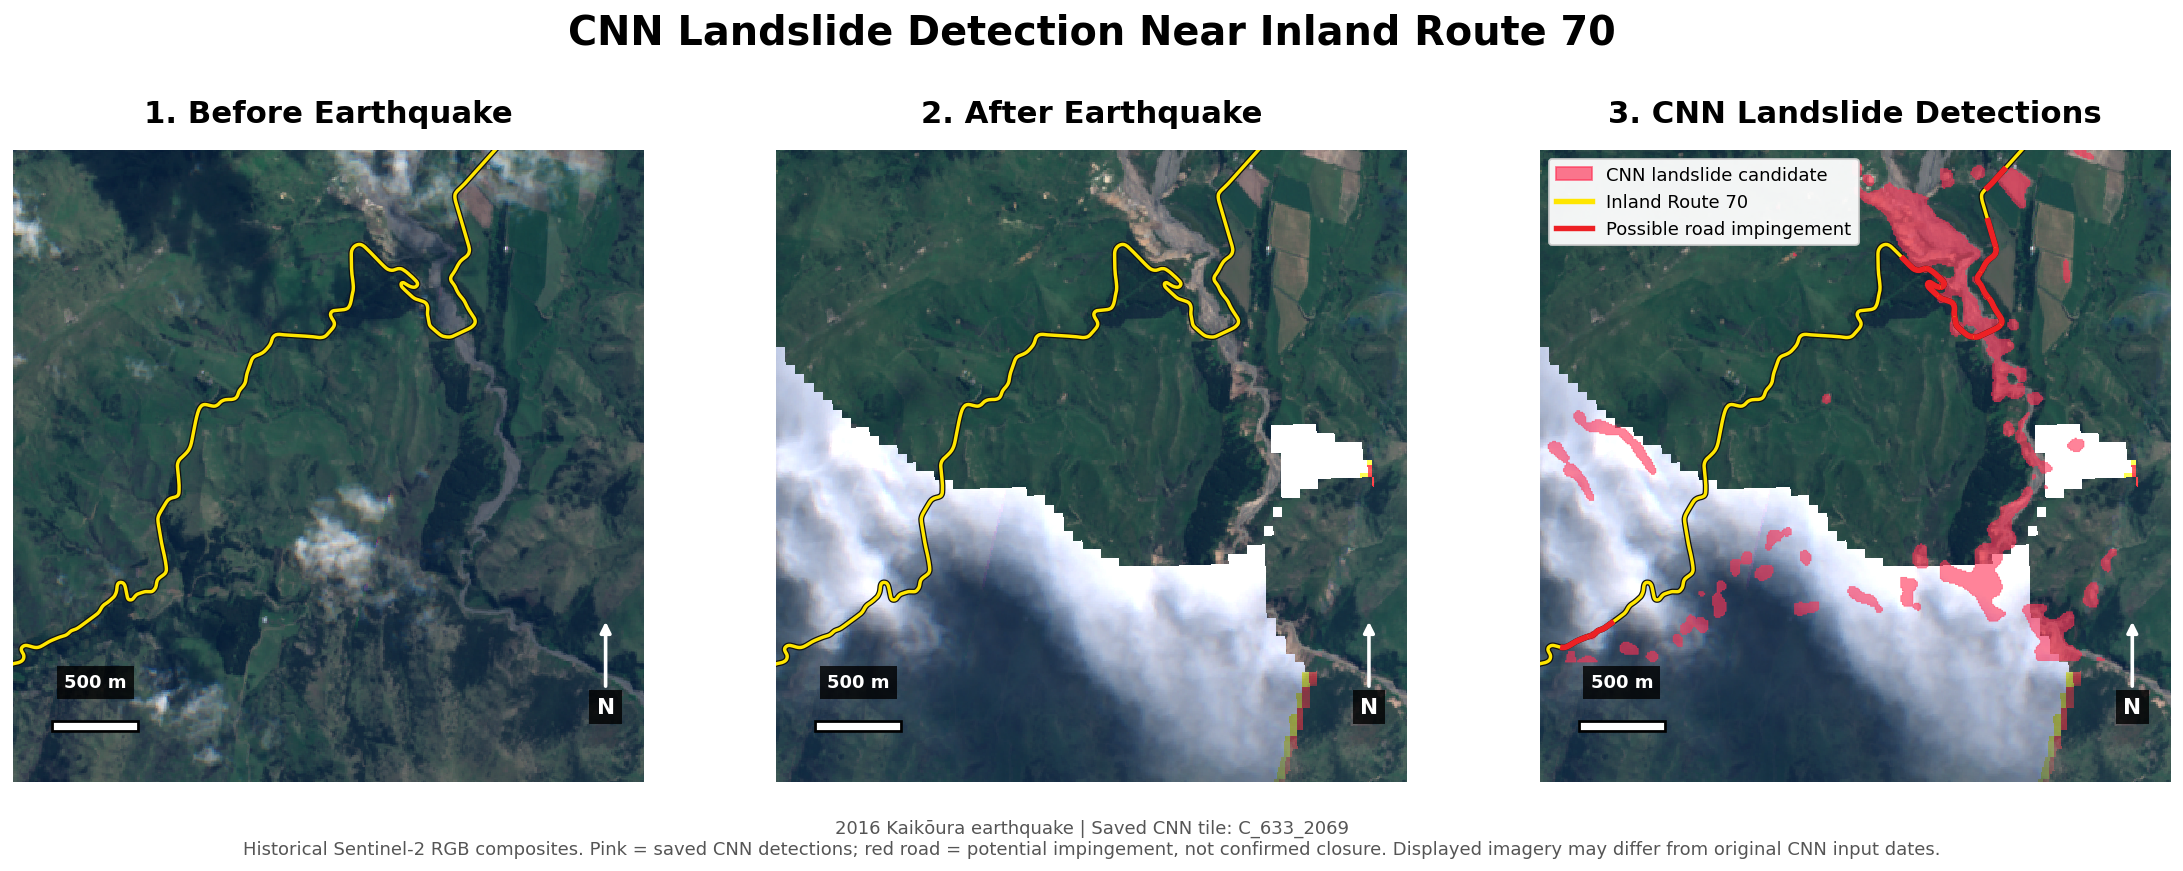


✅ Three-panel figure saved
✅ Saved: 01_BEFORE_ROAD_EXAMPLE.png
✅ Saved: 02_AFTER_ROAD_EXAMPLE.png
✅ Saved: 03_CNN_ROAD_EXAMPLE.png

✅ CNN ROAD-RELATED EXAMPLE COMPLETE

Selected tile: C_633_2069
Red road length: 2520 m
CNN area within 100 m of road: 123626 m²

Main presentation figure:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures/CNN_TILE_DEMONSTRATION/CNN_BEFORE_AFTER_DETECTION_ROAD_EXAMPLE.png

All images saved in:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures/CNN_TILE_DEMONSTRATION

✅ CNN predictions unchanged
✅ Road classifications unchanged
✅ No GNS data
✅ No model inference


In [ ]:
# ================================================================
# CELL 12 — FINAL CNN METHODOLOGY DEMONSTRATION
#
# BEFORE EARTHQUAKE → AFTER EARTHQUAKE → CNN DETECTIONS
#
# IMPROVED EXAMPLE SELECTION:
#   1. Prioritise RED road sections (possible impingement)
#   2. Require CNN detections close to Route 70
#   3. Prefer a substantial visible road section
#   4. Check satellite imagery before accepting the example
#
# OUTPUTS:
#   - One combined three-panel figure
#   - Three individual presentation figures
#
# NO GNS
# NO CNN INFERENCE
# NO MODEL RETRAINING
# ================================================================

from pathlib import Path
from io import BytesIO

import math
import re
import json
import requests

import ee
import rasterio
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from PIL import Image
from shapely.geometry import box
from shapely.ops import unary_union
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display


# ================================================================
# 1. PATHS
# ================================================================

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

R70 = REPO / "outputs/kaikoura_route70"

TILE_DIR = R70 / "tile_results"

ROAD_FILE = R70 / "01_route70_osm_current.geojson"

CNN_FILE = R70 / "03_predicted_landslides.geojson"

RISK_FILE = R70 / "04_SH1_road_assessment.geojson"

OUT = (
    REPO
    / "outputs/final_presentation_figures"
    / "CNN_TILE_DEMONSTRATION"
)

OUT.mkdir(parents=True, exist_ok=True)

for path in [TILE_DIR, ROAD_FILE, CNN_FILE, RISK_FILE]:
    assert path.exists(), f"Missing: {path}"

print("=" * 70)
print("CNN DEMONSTRATION — LANDSLIDE NEAR ROUTE 70")
print("=" * 70)


# ================================================================
# 2. LOAD EXISTING RESULTS
# ================================================================

roads = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:2193")

pred = gpd.read_file(
    CNN_FILE
).to_crs("EPSG:2193")

risk = gpd.read_file(
    RISK_FILE
).to_crs("EPSG:2193")

assert not roads.empty
assert not pred.empty
assert not risk.empty

assert "class" in risk.columns

print("\nLoaded:")
print("CNN polygons:", len(pred))
print("Road segments:", len(risk))

# Actual route geometry
road_union = unary_union(roads.geometry)

# RED sections from the existing CNN-based assessment
red_roads = risk[
    risk["class"] == "possible_impingement"
].copy()

orange_roads = risk[
    risk["class"] == "inspection_priority"
].copy()

assert not red_roads.empty, (
    "No red road sections found."
)

red_union = unary_union(red_roads.geometry)

# Buffer around the actual road.
# Used ONLY for choosing a presentation example.

road_buffer_100m = road_union.buffer(100)

pred_index = pred.sindex

print("Red road segments:", len(red_roads))
print("Orange road segments:", len(orange_roads))

print("\n✅ Existing CNN-based road priorities loaded")
print("✅ No GNS data used")


# ================================================================
# 3. FIND ALL PROCESSED CNN TILES
# ================================================================

tile_files = sorted(
    TILE_DIR.rglob("binary.tif")
)

assert tile_files, "No CNN tiles found."

print("\nSaved CNN tiles:", len(tile_files))


# ================================================================
# 4. RECOVER TILE GEOMETRIES
# ================================================================

def get_tile_geometry(path, src):

    # First try georeferencing saved in the TIFF.

    if src.crs is not None:

        try:

            geometry = box(*src.bounds)

            geometry_m = (
                gpd.GeoSeries(
                    [geometry],
                    crs=src.crs
                )
                .to_crs("EPSG:2193")
                .iloc[0]
            )

            cx = geometry_m.centroid.x
            cy = geometry_m.centroid.y

            if (
                1_000_000 < cx < 2_000_000
                and
                4_800_000 < cy < 5_600_000
            ):
                return geometry_m

        except Exception:
            pass

    # Fallback based on original CNN core-grid naming.

    match = re.search(
        r"C_(-?\d+)_(-?\d+)",
        str(path)
    )

    if match is None:
        return None

    i = int(match.group(1))
    j = int(match.group(2))

    x0 = i * 2560
    y0 = j * 2560

    return box(
        x0,
        y0,
        x0 + 2560,
        y0 + 2560
    )


# ================================================================
# 5. RANK TILES BY ACTUAL ROAD-RELATED LANDSLIDES
# ================================================================

print("\nEvaluating CNN tiles near Route 70...")

tile_candidates = []

for tif_path in tile_files:

    try:

        with rasterio.open(tif_path) as src:

            binary = src.read(1)

            tile_geom = get_tile_geometry(
                tif_path,
                src
            )

        if tile_geom is None:
            continue

        # Actual saved CNN-positive pixels.
        positive_pixels = int(
            (binary == 1).sum()
        )

        # How much real Route 70 passes through the tile?
        road_length = float(
            road_union.intersection(tile_geom).length
        )

        # How much RED road is inside the tile?
        red_length = float(
            red_union.intersection(tile_geom).length
        )

        # CNN polygons intersecting this tile
        hits = pred_index.query(
            tile_geom,
            predicate="intersects"
        )

        nearby = pred.iloc[hits]

        # CNN-detected area within 100 m of road
        near_road_area = 0.0

        # CNN-detected area within 30 m of road
        very_near_area = 0.0

        # Avoid repeatedly creating road buffers
        road_buffer_30m = road_union.buffer(30)

        for geom in nearby.geometry:

            clipped = geom.intersection(tile_geom)

            if clipped.is_empty:
                continue

            near_road_area += (
                clipped
                .intersection(road_buffer_100m)
                .area
            )

            very_near_area += (
                clipped
                .intersection(road_buffer_30m)
                .area
            )

        # We specifically want detections associated
        # with roads, not isolated mountain detections.

        if road_length <= 0:
            continue

        if near_road_area <= 0:
            continue

        # Ranking:
        #
        # Heavily favour RED road sections.
        # Then CNN detections close to the road.
        # Then road length and visible detection area.
        #
        # These are ONLY presentation-selection scores.
        # They do not alter road classifications.

        score = (
            5.0 * red_length
            + 1.5 * min(very_near_area, 10000)
            + 0.5 * min(near_road_area, 20000)
            + 0.2 * road_length
        )

        tile_candidates.append({

            "name": tif_path.parent.name,

            "path": tif_path,

            "geometry": tile_geom,

            "positive_pixels": positive_pixels,

            "road_length_m": road_length,

            "red_length_m": red_length,

            "near_road_area_m2": near_road_area,

            "very_near_area_m2": very_near_area,

            "polygon_count": len(nearby),

            "score": score
        })

    except Exception as exc:

        print(
            "Skipping:",
            tif_path.parent.name,
            str(exc)[:100]
        )


tile_candidates.sort(
    key=lambda x: x["score"],
    reverse=True
)

print("\n" + "=" * 70)
print("BEST ROAD-RELATED CNN TILES")
print("=" * 70)

for candidate in tile_candidates[:10]:

    print(
        f"{candidate['name']} | "
        f"Red road: {candidate['red_length_m']:.0f} m | "
        f"CNN ≤100 m: {candidate['near_road_area_m2']:.0f} m² | "
        f"CNN ≤30 m: {candidate['very_near_area_m2']:.0f} m²"
    )

assert tile_candidates, (
    "No CNN tiles were found with detections "
    "within 100 m of Route 70."
)


# ================================================================
# 6. CONNECT EARTH ENGINE
# ================================================================

EE_PROJECT = "just-terminus-512006-j1"

try:

    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

except Exception:

    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    ee.Number(1).getInfo()

print("\n✅ Earth Engine connected")


# ================================================================
# 7. ORIGINAL WORKING HISTORICAL SATELLITE METHOD
# ================================================================

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


def download_historical_rgb(
    bounds,
    start,
    end,
    use_cloud_mask=True
):

    west, south, east, north = bounds

    region = ee.Geometry.Rectangle([
        west,
        south,
        east,
        north
    ])

    collection = (
        ee.ImageCollection(
            "COPERNICUS/S2_HARMONIZED"
        )
        .filterBounds(region)
        .filterDate(start, end)
    )

    count = collection.size().getInfo()

    if count == 0:
        raise RuntimeError(
            "No Sentinel-2 imagery available."
        )

    if use_cloud_mask:

        collection = collection.map(
            mask_clouds
        )

    # EXACT working approach from our earlier maps.

    mosaic = (
        collection
        .sort(
            "CLOUDY_PIXEL_PERCENTAGE",
            False
        )
        .mosaic()
    )

    rgb = (
        mosaic
        .select(["B4", "B3", "B2"])
        .multiply(0.0001)
        .visualize(
            min=0.02,
            max=0.30,
            gamma=1.15
        )
    )

    width = 1000

    height = max(
        450,
        round(
            width
            * (north - south)
            / (east - west)
        )
    )

    url = rgb.getThumbURL({

        "region": region,

        "dimensions": f"{width}x{height}",

        "crs": "EPSG:4326",

        "format": "png"
    })

    response = requests.get(
        url,
        timeout=180
    )

    response.raise_for_status()

    return Image.open(
        BytesIO(response.content)
    ).convert("RGBA")


# ================================================================
# 8. VERIFY REAL SATELLITE IMAGE COVERAGE
# ================================================================

def check_satellite(image):

    array = np.asarray(image)

    rgb = array[:, :, :3].astype(np.float32)

    alpha = array[:, :, 3]

    valid = alpha > 100

    coverage = float(
        valid.mean()
    )

    if valid.sum() < 1000:

        return False, {
            "coverage": coverage,
            "landscape": 0,
            "variation": 0
        }

    brightness = rgb.mean(axis=2)

    colour_range = (
        rgb.max(axis=2)
        - rgb.min(axis=2)
    )

    landscape_pixels = (
        valid
        & (brightness < 235)
        & (colour_range > 8)
    )

    landscape_fraction = float(
        landscape_pixels.mean()
    )

    pixels = rgb[valid]

    variation = float(
        pixels.std(axis=0).mean()
    )

    good = (
        coverage >= 0.70
        and landscape_fraction >= 0.25
        and variation >= 8
    )

    return good, {
        "coverage": coverage,
        "landscape": landscape_fraction,
        "variation": variation
    }


# ================================================================
# 9. HISTORICAL DATE OPTIONS
# ================================================================

PRE_OPTIONS = [

    ("2016-10-01", "2016-11-14", True),

    ("2016-10-01", "2016-11-14", False),

    ("2016-08-01", "2016-11-14", True),

    ("2016-08-01", "2016-11-14", False)
]


POST_OPTIONS = [

    ("2016-11-20", "2016-12-10", True),

    ("2016-11-20", "2016-12-10", False),

    ("2016-11-14", "2017-01-01", True),

    ("2016-11-14", "2017-01-01", False)
]


def get_visible_satellite(
    bounds,
    options,
    label
):

    for start, end, use_mask in options:

        try:

            image = download_historical_rgb(
                bounds,
                start,
                end,
                use_cloud_mask=use_mask
            )

            good, quality = check_satellite(
                image
            )

            print(
                f"{label}: "
                f"{start} to {end} | "
                f"mask={use_mask} | "
                f"visible={quality['coverage']:.0%} | "
                f"landscape={quality['landscape']:.0%}"
            )

            if good:

                return {
                    "image": image,
                    "start": start,
                    "end": end,
                    "masked": use_mask
                }

        except Exception as exc:

            print(
                "Satellite attempt failed:",
                str(exc)[:140]
            )

    return None


# ================================================================
# 10. FIND A GOOD ROAD-RELATED TILE WITH CLEAR IMAGERY
# ================================================================

selected = None

before = None
after = None

BOUNDS = None

# Prioritise tiles with red road sections.
#
# If none of the first ten have sufficiently visible
# historical imagery, continue through the remaining
# qualifying road-related tiles.

for candidate in tile_candidates:

    print("\n" + "=" * 70)
    print("TRYING ROAD-RELATED TILE:", candidate["name"])
    print("=" * 70)

    print(
        "Red road length:",
        round(candidate["red_length_m"]),
        "m"
    )

    print(
        "CNN detected area ≤100 m from road:",
        round(candidate["near_road_area_m2"]),
        "m²"
    )

    # Add 150 m around the tile, while retaining
    # the same geographic view for both dates.

    view_m = candidate["geometry"].buffer(
        150
    )

    view_wgs = (
        gpd.GeoSeries(
            [view_m],
            crs="EPSG:2193"
        )
        .to_crs("EPSG:4326")
    )

    bounds = tuple(
        float(v)
        for v in view_wgs.total_bounds
    )

    print("\nDownloading BEFORE imagery...")

    pre_candidate = get_visible_satellite(
        bounds,
        PRE_OPTIONS,
        "BEFORE"
    )

    if pre_candidate is None:

        print(
            "No suitable BEFORE imagery. "
            "Trying next tile."
        )

        continue

    print("\nDownloading AFTER imagery...")

    post_candidate = get_visible_satellite(
        bounds,
        POST_OPTIONS,
        "AFTER"
    )

    if post_candidate is None:

        print(
            "No suitable AFTER imagery. "
            "Trying next tile."
        )

        continue

    selected = candidate

    before = pre_candidate

    after = post_candidate

    BOUNDS = bounds

    break


assert selected is not None, (
    "No road-related tile had sufficiently visible "
    "pre/post satellite imagery."
)

print("\n" + "=" * 70)
print("✅ SELECTED ROAD-RELATED CNN EXAMPLE")
print("=" * 70)

print("Tile:", selected["name"])

print(
    "Red road in tile:",
    round(selected["red_length_m"]),
    "m"
)

print(
    "CNN detected area ≤100 m:",
    round(selected["near_road_area_m2"]),
    "m²"
)


# ================================================================
# 11. LOAD ACTUAL CNN AND ROAD GEOMETRIES INSIDE VIEW
# ================================================================

view_geom = (
    gpd.GeoSeries(
        [box(*BOUNDS)],
        crs="EPSG:4326"
    )
    .to_crs("EPSG:2193")
    .iloc[0]
)

pred_view = pred[
    pred.geometry.intersects(
        view_geom
    )
].copy().to_crs("EPSG:4326")

roads_view = roads[
    roads.geometry.intersects(
        view_geom
    )
].copy().to_crs("EPSG:4326")

red_view = red_roads[
    red_roads.geometry.intersects(
        view_geom
    )
].copy().to_crs("EPSG:4326")

print("\nFeatures in view:")
print("CNN polygons:", len(pred_view))
print("Road features:", len(roads_view))
print("Possible impingement sections:", len(red_view))


# ================================================================
# 12. MAP SETTINGS
# ================================================================

WEST, SOUTH, EAST, NORTH = BOUNDS

MID_LAT = (
    SOUTH + NORTH
) / 2

PRED_COLOUR = "#ff3155"

ROAD_COLOUR = "#ffe600"


def add_map_elements(ax):

    # North arrow

    ax.annotate(
        "N",

        xy=(0.94, 0.26),
        xytext=(0.94, 0.11),

        xycoords="axes fraction",
        textcoords="axes fraction",

        ha="center",

        fontsize=12,
        fontweight="bold",

        color="white",

        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2
        ),

        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.80
        ),

        zorder=30
    )

    # 500 m scale bar

    scale_lon = (
        500
        / (
            111320
            * math.cos(
                math.radians(MID_LAT)
            )
        )
    )

    bar_x = WEST + 0.07 * (
        EAST - WEST
    )

    bar_y = SOUTH + 0.09 * (
        NORTH - SOUTH
    )

    ax.plot(
        [bar_x, bar_x + scale_lon],
        [bar_y, bar_y],
        color="black",
        linewidth=7,
        zorder=30
    )

    ax.plot(
        [bar_x, bar_x + scale_lon],
        [bar_y, bar_y],
        color="white",
        linewidth=4,
        zorder=31
    )

    ax.text(
        bar_x + scale_lon / 2,
        bar_y + 0.06 * (NORTH - SOUTH),
        "500 m",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="white",
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8
        ),
        zorder=32
    )


# ================================================================
# 13. DRAW ONE SATELLITE PANEL
# ================================================================

def draw_panel(
    ax,
    satellite,
    show_cnn=False
):

    ax.set_facecolor("#afafaf")

    # Correct geographic display extent:
    # WEST, EAST, SOUTH, NORTH

    ax.imshow(
        np.asarray(satellite),

        extent=(
            WEST,
            EAST,
            SOUTH,
            NORTH
        ),

        origin="upper",
        interpolation="nearest",
        zorder=0
    )

    # CNN predictions only on third panel

    if show_cnn and not pred_view.empty:

        pred_view.plot(
            ax=ax,
            facecolor=PRED_COLOUR,
            edgecolor=PRED_COLOUR,
            linewidth=0.35,
            alpha=0.60,
            zorder=5
        )

    # Route 70 alignment

    if not roads_view.empty:

        roads_view.plot(
            ax=ax,
            color="#111111",
            linewidth=3.3,
            zorder=7
        )

        roads_view.plot(
            ax=ax,
            color=ROAD_COLOUR,
            linewidth=1.9,
            zorder=8
        )

    # Highlight potentially affected road sections
    # only in the detection panel.

    if show_cnn and not red_view.empty:

        red_view.plot(
            ax=ax,
            color="#ed2024",
            linewidth=3.2,
            zorder=10
        )

    ax.set_xlim(WEST, EAST)
    ax.set_ylim(SOUTH, NORTH)

    ax.set_aspect(
        1 / math.cos(
            math.radians(MID_LAT)
        )
    )

    ax.axis("off")

    add_map_elements(ax)


# ================================================================
# 14. CREATE THREE-PANEL PRESENTATION FIGURE
# ================================================================

print("\nGenerating presentation figure...")

fig, axs = plt.subplots(
    1,
    3,
    figsize=(18, 7),
    facecolor="white"
)

draw_panel(
    axs[0],
    before["image"]
)

draw_panel(
    axs[1],
    after["image"]
)

draw_panel(
    axs[2],
    after["image"],
    show_cnn=True
)

axs[0].set_title(
    "1. Before Earthquake",
    fontsize=17,
    fontweight="bold",
    pad=15
)

axs[1].set_title(
    "2. After Earthquake",
    fontsize=17,
    fontweight="bold",
    pad=15
)

axs[2].set_title(
    "3. CNN Landslide Detections",
    fontsize=17,
    fontweight="bold",
    pad=15
)

# Legend on third panel.

axs[2].legend(
    handles=[

        Patch(
            facecolor=PRED_COLOUR,
            edgecolor=PRED_COLOUR,
            alpha=0.65,
            label="CNN landslide candidate"
        ),

        Line2D(
            [0], [0],
            color=ROAD_COLOUR,
            linewidth=3,
            label="Inland Route 70"
        ),

        Line2D(
            [0], [0],
            color="#ed2024",
            linewidth=3,
            label="Possible road impingement"
        )
    ],
    loc="upper left",
    fontsize=10,
    framealpha=0.95
)

fig.suptitle(
    "CNN Landslide Detection Near Inland Route 70",
    fontsize=22,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.045,
    (
        f"2016 Kaikōura earthquake | "
        f"Saved CNN tile: {selected['name']}\n"
        "Historical Sentinel-2 RGB composites. "
        "Pink = saved CNN detections; "
        "red road = potential impingement, not confirmed closure. "
        "Displayed imagery may differ from original CNN input dates."
    ),
    fontsize=10,
    ha="center",
    color="#555555"
)

plt.tight_layout(
    rect=[
        0.01,
        0.10,
        0.99,
        0.91
    ],
    w_pad=2
)

COMBINED_FILE = (
    OUT
    / "CNN_BEFORE_AFTER_DETECTION_ROAD_EXAMPLE.png"
)

fig.savefig(
    COMBINED_FILE,
    dpi=240,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\n✅ Three-panel figure saved")


# ================================================================
# 15. EXPORT THREE INDIVIDUAL IMAGES
# ================================================================

panels = [

    (
        before["image"],
        False,
        "1. Before Earthquake",
        "01_BEFORE_ROAD_EXAMPLE.png"
    ),

    (
        after["image"],
        False,
        "2. After Earthquake",
        "02_AFTER_ROAD_EXAMPLE.png"
    ),

    (
        after["image"],
        True,
        "3. CNN Landslide Detections",
        "03_CNN_ROAD_EXAMPLE.png"
    )
]

for satellite, show_cnn, title, filename in panels:

    fig, ax = plt.subplots(
        figsize=(9, 8),
        facecolor="white"
    )

    draw_panel(
        ax,
        satellite,
        show_cnn=show_cnn
    )

    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=15
    )

    output = OUT / filename

    fig.savefig(
        output,
        dpi=240,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.close(fig)

    print("✅ Saved:", filename)


# ================================================================
# 16. SAVE SELECTION INFORMATION
# ================================================================

metadata = {

    "tile": selected["name"],

    "red_road_length_m": float(
        selected["red_length_m"]
    ),

    "cnn_detected_area_within_100m_m2": float(
        selected["near_road_area_m2"]
    ),

    "cnn_detected_area_within_30m_m2": float(
        selected["very_near_area_m2"]
    ),

    "before_period": [
        before["start"],
        before["end"]
    ],

    "after_period": [
        after["start"],
        after["end"]
    ],

    "cnn_rerun": False,

    "gns_used": False
}

(
    OUT / "CNN_ROAD_EXAMPLE_METADATA.json"
).write_text(
    json.dumps(metadata, indent=2)
)


# ================================================================
# 17. FINISHED
# ================================================================

print("\n" + "=" * 70)
print("✅ CNN ROAD-RELATED EXAMPLE COMPLETE")
print("=" * 70)

print("\nSelected tile:", selected["name"])

print(
    "Red road length:",
    round(selected["red_length_m"]),
    "m"
)

print(
    "CNN area within 100 m of road:",
    round(selected["near_road_area_m2"]),
    "m²"
)

print("\nMain presentation figure:")
print(COMBINED_FILE)

print("\nAll images saved in:")
print(OUT)

print("\n✅ CNN predictions unchanged")
print("✅ Road classifications unchanged")
print("✅ No GNS data")
print("✅ No model inference")

GENERATING FIVE CNN EXAMPLES
CNN polygons: 642
CNN tiles: 58
Red road segments: 38

TOP ROAD-RELATED CNN TILES
C_626_2062 | Red road: 1597 m | CNN ≤30 m: 18617 m² | CNN ≤100 m: 92462 m²
C_627_2062 | Red road: 1397 m | CNN ≤30 m: 17533 m² | CNN ≤100 m: 83101 m²
C_633_2069 | Red road: 2520 m | CNN ≤30 m: 37377 m² | CNN ≤100 m: 123626 m²
C_633_2070 | Red road: 2195 m | CNN ≤30 m: 35333 m² | CNN ≤100 m: 119908 m²
C_634_2070 | Red road: 1496 m | CNN ≤30 m: 22098 m² | CNN ≤100 m: 79129 m²
C_628_2064 | Red road: 1197 m | CNN ≤30 m: 14174 m² | CNN ≤100 m: 75304 m²
C_634_2069 | Red road: 1447 m | CNN ≤30 m: 22043 m² | CNN ≤100 m: 77450 m²
C_627_2064 | Red road: 917 m | CNN ≤30 m: 7476 m² | CNN ≤100 m: 50502 m²
C_636_2072 | Red road: 798 m | CNN ≤30 m: 6429 m² | CNN ≤100 m: 40776 m²
C_637_2072 | Red road: 599 m | CNN ≤30 m: 5695 m² | CNN ≤100 m: 53469 m²

✅ Earth Engine connected

TRYING: C_626_2062
Getting BEFORE satellite...
Getting AFTER satellite...
✅ OPTION 1 saved: OPTION_1_CNN_EXAMPLE.png

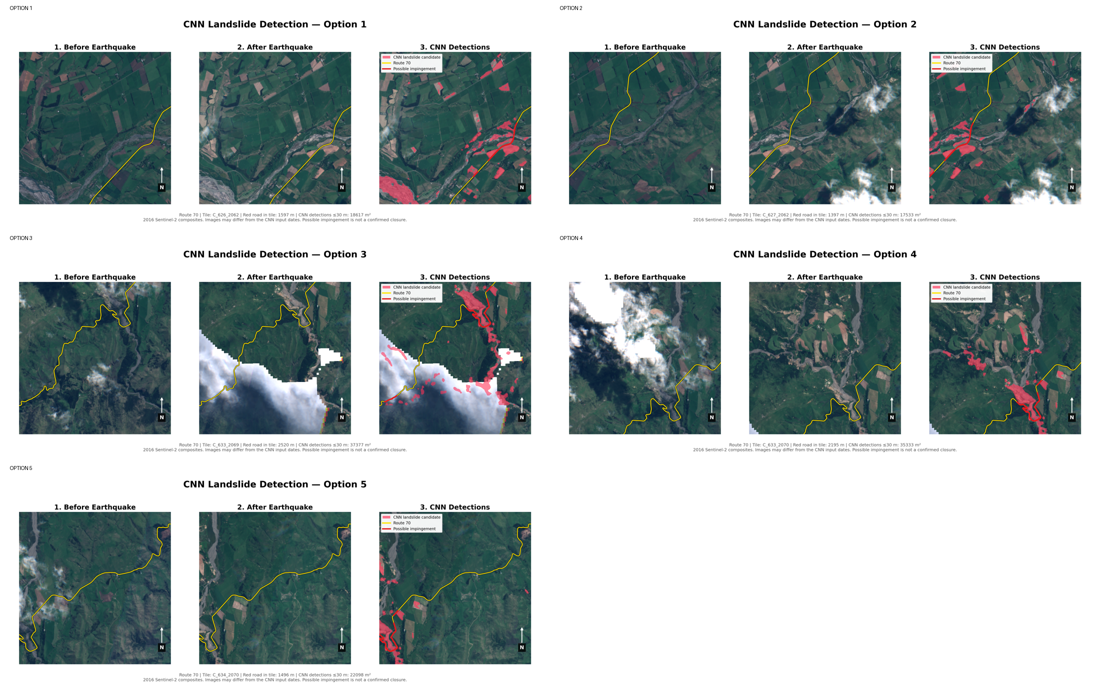


✅ COMPLETE

Examples created: 5

Overview:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures/FIVE_CNN_EXAMPLES/00_ALL_FIVE_OPTIONS_OVERVIEW.png

Individual figures:
✅ OPTION_1_CNN_EXAMPLE.png
✅ OPTION_2_CNN_EXAMPLE.png
✅ OPTION_3_CNN_EXAMPLE.png
✅ OPTION_4_CNN_EXAMPLE.png
✅ OPTION_5_CNN_EXAMPLE.png

Saved in:
/content/drive/MyDrive/GEOG761/igarss-landslide-delineation/outputs/final_presentation_figures/FIVE_CNN_EXAMPLES

✅ No GNS
✅ No CNN rerun
✅ Existing CNN predictions


In [ ]:
# ================================================================
# CELL 13 — FIVE CNN EXAMPLES FOR PRESENTATION
#
# Generate 5 different Route 70 examples:
# BEFORE → AFTER → CNN DETECTIONS
#
# Prioritises:
#   - CNN detections close to the road
#   - Red road sections (possible impingement)
#   - Visible road alignment
#   - Usable historical satellite imagery
#
# OUTPUTS:
#   5 separate three-panel figures
#   1 overview image showing all 5 options
#
# NO GNS
# NO CNN INFERENCE
# ================================================================

from pathlib import Path
from io import BytesIO
import math
import re
import json
import requests

import ee
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ImageDraw
from shapely.geometry import box
from shapely.ops import unary_union
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display


# ================================================================
# 1. PATHS
# ================================================================

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

R70 = REPO / "outputs/kaikoura_route70"

TILE_DIR = R70 / "tile_results"

ROAD_FILE = R70 / "01_route70_osm_current.geojson"
CNN_FILE = R70 / "03_predicted_landslides.geojson"
RISK_FILE = R70 / "04_SH1_road_assessment.geojson"

OUT = (
    REPO
    / "outputs/final_presentation_figures"
    / "FIVE_CNN_EXAMPLES"
)

OUT.mkdir(parents=True, exist_ok=True)

for path in [TILE_DIR, ROAD_FILE, CNN_FILE, RISK_FILE]:
    assert path.exists(), f"Missing: {path}"

print("=" * 65)
print("GENERATING FIVE CNN EXAMPLES")
print("=" * 65)


# ================================================================
# 2. LOAD EXISTING DATA
# ================================================================

roads = gpd.read_file(
    ROAD_FILE
).to_crs("EPSG:2193")

pred = gpd.read_file(
    CNN_FILE
).to_crs("EPSG:2193")

risk = gpd.read_file(
    RISK_FILE
).to_crs("EPSG:2193")

red_roads = risk[
    risk["class"] == "possible_impingement"
].copy()

assert not red_roads.empty

road_union = unary_union(roads.geometry)
red_union = unary_union(red_roads.geometry)

road_buffer_30 = road_union.buffer(30)
road_buffer_100 = road_union.buffer(100)

pred_index = pred.sindex

tile_files = sorted(TILE_DIR.rglob("binary.tif"))

print("CNN polygons:", len(pred))
print("CNN tiles:", len(tile_files))
print("Red road segments:", len(red_roads))


# ================================================================
# 3. RECOVER ACTUAL CNN TILE GEOMETRIES
# ================================================================

def get_tile_geometry(path, src):

    if src.crs is not None:

        try:

            geom = (
                gpd.GeoSeries(
                    [box(*src.bounds)],
                    crs=src.crs
                )
                .to_crs("EPSG:2193")
                .iloc[0]
            )

            c = geom.centroid

            if (
                1_000_000 < c.x < 2_000_000
                and
                4_800_000 < c.y < 5_600_000
            ):
                return geom

        except Exception:
            pass

    match = re.search(
        r"C_(-?\d+)_(-?\d+)",
        str(path)
    )

    if match is None:
        return None

    i, j = map(int, match.groups())

    x0 = i * 2560
    y0 = j * 2560

    return box(
        x0,
        y0,
        x0 + 2560,
        y0 + 2560
    )


# ================================================================
# 4. RANK TILES BY LANDSLIDE DETECTIONS NEAR THE ROAD
# ================================================================

candidates = []

for tif_path in tile_files:

    try:

        with rasterio.open(tif_path) as src:

            geom = get_tile_geometry(tif_path, src)

            positive = int(
                (src.read(1) == 1).sum()
            )

        if geom is None:
            continue

        # Road length inside tile
        road_length = float(
            road_union.intersection(geom).length
        )

        # Red road length inside tile
        red_length = float(
            red_union.intersection(geom).length
        )

        # Only tiles with actual road geometry
        if road_length <= 0:
            continue

        hits = pred_index.query(
            geom,
            predicate="intersects"
        )

        near_30 = 0.0
        near_100 = 0.0

        for idx in hits:

            p = pred.geometry.iloc[int(idx)]

            clipped = p.intersection(geom)

            if clipped.is_empty:
                continue

            near_30 += (
                clipped.intersection(
                    road_buffer_30
                ).area
            )

            near_100 += (
                clipped.intersection(
                    road_buffer_100
                ).area
            )

        # Require detections close to Route 70
        if near_100 <= 0:
            continue

        # Strong preference for actual road proximity.
        # These scores ONLY select presentation examples.
        score = (
            100000 * (red_length > 20)
            + 40 * min(red_length, 800)
            + 2 * min(near_30, 15000)
            + 0.4 * min(near_100, 20000)
            + 5 * min(road_length, 3000)
        )

        candidates.append({

            "tile": tif_path.parent.name,
            "geometry": geom,

            "score": score,

            "road_m": road_length,
            "red_m": red_length,

            "near30_m2": near_30,
            "near100_m2": near_100,

            "positive_pixels": positive
        })

    except Exception as exc:

        print(
            "Skipping tile:",
            tif_path.parent.name,
            str(exc)[:100]
        )


candidates.sort(
    key=lambda c: c["score"],
    reverse=True
)

assert candidates, (
    "No CNN tiles with detections near Route 70."
)

print("\nTOP ROAD-RELATED CNN TILES")

for c in candidates[:10]:

    print(
        f"{c['tile']} | "
        f"Red road: {c['red_m']:.0f} m | "
        f"CNN ≤30 m: {c['near30_m2']:.0f} m² | "
        f"CNN ≤100 m: {c['near100_m2']:.0f} m²"
    )


# ================================================================
# 5. CONNECT EARTH ENGINE
# ================================================================

PROJECT = "just-terminus-512006-j1"

try:

    ee.Initialize(project=PROJECT)
    ee.Number(1).getInfo()

except Exception:

    ee.Authenticate()
    ee.Initialize(project=PROJECT)
    ee.Number(1).getInfo()

print("\n✅ Earth Engine connected")


# ================================================================
# 6. HISTORICAL SATELLITE FUNCTION
# ================================================================

def mask_clouds(image):

    qa = image.select("QA60")

    clear = (
        qa.bitwiseAnd(1 << 10).eq(0)
        .And(
            qa.bitwiseAnd(1 << 11).eq(0)
        )
    )

    return image.updateMask(clear)


def download_rgb(bounds, start, end, use_mask):

    west, south, east, north = bounds

    region = ee.Geometry.Rectangle([
        west, south, east, north
    ])

    collection = (
        ee.ImageCollection(
            "COPERNICUS/S2_HARMONIZED"
        )
        .filterBounds(region)
        .filterDate(start, end)
    )

    if collection.size().getInfo() == 0:
        raise RuntimeError("No satellite scenes")

    if use_mask:
        collection = collection.map(mask_clouds)

    mosaic = (
        collection
        .sort("CLOUDY_PIXEL_PERCENTAGE", False)
        .mosaic()
    )

    rgb = (
        mosaic
        .select(["B4", "B3", "B2"])
        .multiply(0.0001)
        .visualize(
            min=0.02,
            max=0.30,
            gamma=1.15
        )
    )

    width = 850

    height = max(
        400,
        round(
            width * (north - south) / (east - west)
        )
    )

    url = rgb.getThumbURL({
        "region": region,
        "dimensions": f"{width}x{height}",
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        url,
        timeout=150
    )

    response.raise_for_status()

    return Image.open(
        BytesIO(response.content)
    ).convert("RGBA")


# ================================================================
# 7. SATELLITE QUALITY CHECK
# ================================================================

def satellite_quality(image):

    arr = np.asarray(image)

    rgb = arr[:, :, :3].astype(np.float32)
    alpha = arr[:, :, 3]

    visible = alpha > 100

    coverage = float(visible.mean())

    if visible.sum() < 1000:
        return False

    brightness = rgb.mean(axis=2)

    colour_range = (
        rgb.max(axis=2)
        - rgb.min(axis=2)
    )

    landscape = (
        visible
        & (brightness < 235)
        & (colour_range > 8)
    )

    landscape_fraction = float(
        landscape.mean()
    )

    variation = float(
        rgb[visible].std(axis=0).mean()
    )

    return (
        coverage >= 0.70
        and landscape_fraction >= 0.25
        and variation >= 8
    )


# ================================================================
# 8. HISTORICAL IMAGE WINDOWS
# ================================================================

PRE_OPTIONS = [
    ("2016-10-01", "2016-11-14", True),
    ("2016-10-01", "2016-11-14", False),
    ("2016-08-01", "2016-11-14", True),
    ("2016-08-01", "2016-11-14", False)
]

POST_OPTIONS = [
    ("2016-11-20", "2016-12-10", True),
    ("2016-11-20", "2016-12-10", False),
    ("2016-11-14", "2017-01-01", True),
    ("2016-11-14", "2017-01-01", False)
]


def get_image(bounds, options):

    for start, end, mask in options:

        try:

            img = download_rgb(
                bounds,
                start,
                end,
                mask
            )

            if satellite_quality(img):

                return {
                    "image": img,
                    "start": start,
                    "end": end,
                    "masked": mask
                }

        except Exception as exc:

            print(
                "  Satellite attempt:",
                str(exc)[:100]
            )

    return None


# ================================================================
# 9. MAP DRAWING FUNCTION
# ================================================================

def draw_panel(
    ax,
    satellite,
    bounds,
    road_view,
    pred_view,
    red_view,
    show_cnn=False
):

    west, south, east, north = bounds

    midlat = (south + north) / 2

    ax.set_facecolor("#afafaf")

    ax.imshow(
        np.asarray(satellite),
        extent=(west, east, south, north),
        origin="upper",
        interpolation="nearest",
        zorder=0
    )

    # CNN predictions only on detection panel
    if show_cnn and not pred_view.empty:

        pred_view.plot(
            ax=ax,
            facecolor="#ff3155",
            edgecolor="#ff3155",
            linewidth=0.3,
            alpha=0.58,
            zorder=5
        )

    # Road alignment
    if not road_view.empty:

        road_view.plot(
            ax=ax,
            color="#151515",
            linewidth=3,
            zorder=7
        )

        road_view.plot(
            ax=ax,
            color="#ffe600",
            linewidth=1.7,
            zorder=8
        )

    # Possible impingement shown only on detection panel
    if show_cnn and not red_view.empty:

        red_view.plot(
            ax=ax,
            color="#e31a1c",
            linewidth=3.3,
            zorder=9
        )

    ax.set_xlim(west, east)
    ax.set_ylim(south, north)

    ax.set_aspect(
        1 / math.cos(math.radians(midlat))
    )

    ax.axis("off")

    # North arrow
    ax.annotate(
        "N",
        xy=(0.94, 0.25),
        xytext=(0.94, 0.10),
        xycoords="axes fraction",
        textcoords="axes fraction",
        fontsize=12,
        ha="center",
        fontweight="bold",
        color="white",
        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=2
        ),
        bbox=dict(
            facecolor="black",
            edgecolor="none",
            alpha=0.8
        ),
        zorder=30
    )


# ================================================================
# 10. GENERATE FIVE DIFFERENT EXAMPLES
# ================================================================

OUTPUT_FILES = []
RESULTS = []

MAX_EXAMPLES = 5

# Check the highest-ranked 25 tiles if necessary.
# Stop immediately once five usable examples are found.

for candidate in candidates[:25]:

    if len(OUTPUT_FILES) >= MAX_EXAMPLES:
        break

    tile = candidate["tile"]

    print("\n" + "=" * 65)
    print("TRYING:", tile)
    print("=" * 65)

    # Slightly expand the tile to show surrounding terrain
    view_m = candidate["geometry"].buffer(150)

    view_wgs = (
        gpd.GeoSeries(
            [view_m],
            crs="EPSG:2193"
        )
        .to_crs("EPSG:4326")
    )

    bounds = tuple(
        float(v) for v in view_wgs.total_bounds
    )

    # Retrieve historical images
    print("Getting BEFORE satellite...")
    before = get_image(bounds, PRE_OPTIONS)

    if before is None:
        print("Skipping: unclear BEFORE image")
        continue

    print("Getting AFTER satellite...")
    after = get_image(bounds, POST_OPTIONS)

    if after is None:
        print("Skipping: unclear AFTER image")
        continue

    # Extract existing CNN polygons and roads
    view_geom = view_m

    pred_view = pred[
        pred.geometry.intersects(view_geom)
    ].copy().to_crs("EPSG:4326")

    road_view = roads[
        roads.geometry.intersects(view_geom)
    ].copy().to_crs("EPSG:4326")

    red_view = red_roads[
        red_roads.geometry.intersects(view_geom)
    ].copy().to_crs("EPSG:4326")

    option_number = len(OUTPUT_FILES) + 1

    # --------------------------------------------------------
    # MAKE THREE-PANEL FIGURE
    # --------------------------------------------------------

    fig, axs = plt.subplots(
        1,
        3,
        figsize=(18, 7),
        facecolor="white"
    )

    draw_panel(
        axs[0],
        before["image"],
        bounds,
        road_view,
        pred_view,
        red_view,
        show_cnn=False
    )

    draw_panel(
        axs[1],
        after["image"],
        bounds,
        road_view,
        pred_view,
        red_view,
        show_cnn=False
    )

    draw_panel(
        axs[2],
        after["image"],
        bounds,
        road_view,
        pred_view,
        red_view,
        show_cnn=True
    )

    axs[0].set_title(
        "1. Before Earthquake",
        fontsize=16,
        fontweight="bold"
    )

    axs[1].set_title(
        "2. After Earthquake",
        fontsize=16,
        fontweight="bold"
    )

    axs[2].set_title(
        "3. CNN Detections",
        fontsize=16,
        fontweight="bold"
    )

    axs[2].legend(
        handles=[
            Patch(
                facecolor="#ff3155",
                alpha=0.65,
                label="CNN landslide candidate"
            ),
            Line2D(
                [0], [0],
                color="#ffe600",
                linewidth=3,
                label="Route 70"
            ),
            Line2D(
                [0], [0],
                color="#e31a1c",
                linewidth=3,
                label="Possible impingement"
            )
        ],
        loc="upper left",
        fontsize=9,
        framealpha=0.95
    )

    fig.suptitle(
        f"CNN Landslide Detection — Option {option_number}",
        fontsize=21,
        fontweight="bold",
        y=0.97
    )

    fig.text(
        0.5,
        0.035,
        (
            f"Route 70 | Tile: {tile} | "
            f"Red road in tile: {candidate['red_m']:.0f} m | "
            f"CNN detections ≤30 m: "
            f"{candidate['near30_m2']:.0f} m²\n"
            "2016 Sentinel-2 composites. "
            "Images may differ from the CNN input dates. "
            "Possible impingement is not a confirmed closure."
        ),
        ha="center",
        fontsize=10,
        color="#555555"
    )

    plt.tight_layout(
        rect=[0.01, 0.09, 0.99, 0.91],
        w_pad=2
    )

    output = (
        OUT
        / f"OPTION_{option_number}_CNN_EXAMPLE.png"
    )

    fig.savefig(
        output,
        dpi=220,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.close(fig)

    OUTPUT_FILES.append(output)

    RESULTS.append({
        "option": option_number,
        "tile": tile,
        "red_road_m": candidate["red_m"],
        "road_length_m": candidate["road_m"],
        "cnn_near_30m_m2": candidate["near30_m2"],
        "cnn_near_100m_m2": candidate["near100_m2"],
        "before_period": (
            f"{before['start']} to {before['end']}"
        ),
        "after_period": (
            f"{after['start']} to {after['end']}"
        ),
        "file": str(output)
    })

    print(
        f"✅ OPTION {option_number} saved:",
        output.name
    )


# ================================================================
# 11. CREATE OVERVIEW OF ALL FIVE OPTIONS
# ================================================================

assert OUTPUT_FILES, (
    "No examples had usable historical imagery."
)

THUMB_WIDTH = 1100
THUMB_HEIGHT = 460

OVERVIEW = Image.new(
    "RGB",
    (THUMB_WIDTH * 2, THUMB_HEIGHT * 3),
    "white"
)

drawer = ImageDraw.Draw(OVERVIEW)

for i, path in enumerate(OUTPUT_FILES):

    img = Image.open(path).convert("RGB")

    img.thumbnail(
        (THUMB_WIDTH - 25, THUMB_HEIGHT - 45)
    )

    col = i % 2
    row = i // 2

    x = col * THUMB_WIDTH
    y = row * THUMB_HEIGHT

    overview_x = (
        x + (THUMB_WIDTH - img.width) // 2
    )

    overview_y = y + 35

    OVERVIEW.paste(
        img,
        (overview_x, overview_y)
    )

    drawer.text(
        (x + 20, y + 10),
        f"OPTION {i + 1}",
        fill="black"
    )

OVERVIEW_FILE = (
    OUT / "00_ALL_FIVE_OPTIONS_OVERVIEW.png"
)

OVERVIEW.save(OVERVIEW_FILE)

print("\n" + "=" * 65)
print("FIVE CNN EXAMPLES — OVERVIEW")
print("=" * 65)

display(
    OVERVIEW.resize(
        (
            1100,
            round(
                OVERVIEW.height * 1100 / OVERVIEW.width
            )
        )
    )
)


# ================================================================
# 12. SAVE SUMMARY
# ================================================================

results_df = pd.DataFrame(RESULTS)

results_df.to_csv(
    OUT / "FIVE_EXAMPLE_STATISTICS.csv",
    index=False
)

print("\n" + "=" * 65)
print("✅ COMPLETE")
print("=" * 65)

print("\nExamples created:", len(OUTPUT_FILES))

print("\nOverview:")
print(OVERVIEW_FILE)

print("\nIndividual figures:")

for path in OUTPUT_FILES:
    print("✅", path.name)

print("\nSaved in:")
print(OUT)

print("\n✅ No GNS")
print("✅ No CNN rerun")
print("✅ Existing CNN predictions")

In [ ]:
from pathlib import Path
import json

REPO = Path(
    "/content/drive/MyDrive/GEOG761/"
    "igarss-landslide-delineation"
)

for corridor in [
    "kaikoura_route70",
    "kaikoura_full_coast_SH1"
]:

    folder = REPO / "outputs" / corridor

    print("\n" + "=" * 70)
    print(corridor.upper())
    print("=" * 70)

    files = sorted(folder.rglob("*.json"))

    print("JSON files found:", len(files))

    for file in files:

        try:
            data = json.loads(file.read_text())
        except Exception:
            continue

        def find_dates(obj, prefix=""):

            if isinstance(obj, dict):

                for key, value in obj.items():

                    name = f"{prefix}.{key}" if prefix else key

                    if any(
                        term in key.lower()
                        for term in [
                            "date",
                            "time",
                            "scene",
                            "acquisition",
                            "image_id",
                            "pre_id",
                            "post_id"
                        ]
                    ) and not isinstance(value, (dict, list)):

                        print(f"  {name}: {value}")

                    elif isinstance(value, (dict, list)):
                        find_dates(value, name)

            elif isinstance(obj, list):

                for item in obj[:5]:
                    find_dates(item, prefix)

        # Only print metadata that contains date-related fields.
        import io
        from contextlib import redirect_stdout

        buffer = io.StringIO()

        with redirect_stdout(buffer):
            find_dates(data)

        result = buffer.getvalue()

        if result.strip():

            print("\nFILE:", file.relative_to(folder))
            print(result[:2500])


KAIKOURA_ROUTE70
JSON files found: 60

FILE: tile_results/C_625_2061/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_626_2061/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_626_2062/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_626_2063/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_627_2061/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_627_2062/status.json
  pre.date: 2016-10-26
  pre.scene_cloud_pct: 17.9613
  post.date: 2016-11-25
  post.scene_cloud_pct: 20.9244


FILE: tile_results/C_627_2063/status